# 36 Feature Engineering: Zeitstruktur und Erklärbarkeit

Teil 8: Modellvergleich und Ergebnis

**Worum es geht**

Notebook 35 (Abschnitt 18) zeigt, dass bei Filter, Durchfluss und Sollwert weder eine Regel noch die KI etwas findet. Bei der Dämmung findet die KI ein Muster, das sich nicht erklären lässt. Liegt das an den Daten, an den Kennzahlen oder an den Labels? Normalerweise steckt die meiste Arbeit im Feature Engineering, im Projekt war das aber nur beim Ventil gezielt der Fall. Dieses Notebook holt das nach.

Vier Fragen leiten es. Ändert sich nach der Begehung die Größe, die die Maßnahme ändern müsste? Wenn nicht, bedeutet das Label in den Daten wenig, und kein Modell kann es lernen. Was zeigen eine gleitende Korrelation und eine Zerlegung des Verbrauchs in Grundlast, Wetteranteil und Trend? Hilft je Befund eine neue Kennzahl aus der Physik mit vorher festgelegter Richtung, allein oder in der Regression? Und welche Kennzahlen kombiniert die KI bei der Dämmung, gemessen mit SHAP?

Für Aussagen zur Erkennung gelten die Zahlen aus Notebook 35 (Ventil 0,84, Dämmung 0,78 mit Modellwahl im Lernteil). Die Spalte „KI“ in den Abschnitten 0 und 9 ist die Regression auf Kennzahlen und LSTM-Zahlen.

**Daten**
- liest: Stundenreihen und Labels wie Notebook 35 (`fv.lade_eingaben`, Labels aus Notebook 25), aus `outputs/finalvergleich/` die Vorhersagen aus Test C und den Vergleich KI gegen Regel, die Paket-Variante `fehlerklassen` mit Kennzahlen und LSTM-Zahlen aus `models/`
- schreibt: Tabellen und Abbildungen nach `outputs/merkmalsbau/`
- vorher ausführen: Notebook 00, 25 und 35

**Code**
- Logik in `src/merkmalsbau.py`, Tests in `tests/test_merkmalsbau.py` mit künstlichen Daten, deren Ergebnis bekannt ist

## 0 · Ergebnisse im Überblick

| Frage | Antwort |
|---|---|
| Bewirken die Maßnahmen etwas Messbares? | Nur der **Ventiltausch** klar: Der Durchfluss in Sommernächten sinkt (AUC 0,81, nach Holm gesichert). Beim Sollwert höchstens eine Andeutung. **Dämmung, Filter und Durchfluss hinterlassen keine messbare Spur.** Das Placebo (Vertrag) findet richtigerweise nichts. |
| Wie gut sind die Labels? | Sollwert (62 %) und Filter (47 %) wurden bei so vielen Begehungen gemacht, dass sie eher Routine sind als gefundene Fehler. „Gemacht“ heißt nicht „war kaputt“. |
| Gleitende Korrelation | Zeigt Einzelfälle sehr deutlich: An Station 68956351 dreht sich die Kopplung durch den Ventiltausch von −0,9 auf +0,75. Über alle Ventile trennt sie aber nicht (0,50). |
| Zerlegung in Grundlast, Wetter und Trend | Wetterbereinigt sinkt der Verbrauch nach dem Dämmen nicht messbar. |
| Neue Kennzahlen | Die **Abkühlrate im Stillstand** erkennt die Dämmung mit 0,69 in die vorher festgelegte Richtung, nach Holm nicht gesichert. Die Filter-Sättigung geht mit 0,62 zum ersten Mal in die vermutete Richtung, auch nicht gesichert. Sonst nichts. |
| Nachprüfung Abkühlrate | Nach dem Dämmen kühlt stehendes Wasser langsamer ab, bei 9 von 10 Stationen. Nachträglich ergänzt und abhängig von einer fragwürdigen Messung: ein Hinweis, kein Beweis. |
| Regression mit neuen Kennzahlen | Dämmung 0,74 → 0,89. Das trägt aber eine Kennzahl (Volllaststunden), die für etwas anderes geplant war und je nach Bezugsgröße nur +0,06 bringt. **Kein Ergebnis.** |
| SHAP | Die KI erkennt die Dämmung an einem stabilen Muster (kälterer Rücklauf, kleine Spreizung in Sommernächten, große Streubreite), in allen fünf Durchgängen gleich und auch ohne Ventilstationen (0,80). In der Paket-Variante mit Kennzahlen und LSTM-Zahlen tragen die 16 LSTM-Zahlen etwa die Hälfte. |
| Steckt ein äußerer Faktor dahinter? | Mit den vorhandenen Angaben nein. Innerhalb von Stationstyp, Anlagenkennziffer, Größe, Zusatzheizung und Zeitraum der Begehung trennt die KI weiter mit 0,75 bis 0,86. Leere Kästchen heißen meist wirklich „nicht gedämmt“. Das Baujahr fehlt bei den meisten Stationen, dort bleibt es offen. |

Kurz gesagt hilft besseres Feature Engineering dort, wo die Physik eine Spur im Zähler hinterlässt. Bei der Dämmung gibt es jetzt einen ersten physikalischen Hinweis, die Abkühlrate. Bei Filter, Durchfluss und Sollwert hinterlassen schon die Maßnahmen selbst keine messbare Spur, dort helfen eher bessere Labels als bessere Kennzahlen.

In [1]:
import os as _os
from pathlib import Path as _Path
#Arbeitsordner ist immer notebooks/, auch aus den Teil-Ordnern
_os.chdir(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "src").is_dir()) / "notebooks")
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "merkmalsbau.py").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")

from src import fehlerklassen as fk
from src import finalvergleich as fv
from src import merkmalsbau as mb

AUSGABE = ROOT / "outputs" / "merkmalsbau"
BILDER = AUSGABE / "abbildungen"
BILDER.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 110)

## 1 · Spielregeln und Plan

Mit 53 begangenen Stationen findet man fast immer irgendeine Kennzahl, die zufällig passt, wenn man nur lange genug sucht. Deshalb steht für jeden Befund vorher fest, welche Größe angeschaut wird und in welche Richtung sie gehen soll. Geht sie in die andere Richtung, zählt das als „Vermutung falsch“ und wird nicht umgedreht. Der Plan steht in `src/merkmalsbau.py` (`PLAN_WIRKUNG`, `PLAN_KENNZAHLEN`, `PLAN_ZUSATZ`) und wurde geschrieben, bevor eine dieser Größen mit den Labels verglichen wurde.

Die Ideen kommen aus dem, was vorher schon bekannt war. Die Messlatte aus Notebook 25 (Abschnitt 8) mit je einer einfachen Kennzahl zeigt Ventil (Nachtdurchfluss, AUC 0,88) und Vertrag (Auslastung, 0,78) gut erkennbar, die Dämmung schwach (kälterer Rücklauf, 0,64), den Sollwert höchstens angedeutet (Rücklauf tagsüber, 0,60), den Durchfluss bei Raten (Durchfluss je kW, 0,50) und den Filter falsch vermutet (höhere Spreizung, 0,36). In Notebook 25 (Abschnitt 6) gab es an je einer Beispielstation nach der Dämmung keine sichtbare Änderung, nach der Filterreinigung an kalten Tagen etwas mehr Durchfluss, nach dem Einstellen des Durchflusses bei mittleren Temperaturen weniger und nach dem Senken des Sollwerts tagsüber 1 bis 3 K kälteren Rücklauf. Notebook 02 vergleicht den Rücklauf 21 Tage vor und nach der Begehung, die Änderung passt zur Kategorie, ist aber nicht gesichert. Die neuen Kennzahlen sind andere Größen als in Notebook 25. Die erwarteten Wirkungen folgen der Physik und passen zu den Andeutungen aus Notebook 25, die dort aber nur an je einer Station zu sehen waren.

Maß ist die AUC mit vorher festgelegter Richtung, 0,5 ist Raten, 1 perfekt und unter 0,5 heißt Vermutung falsch. Das 95-%-Intervall kommt aus dem Ziehen ganzer Stationen wie in Notebook 35, dazu kommt ein Zufallstest, in wie vielen von 5000 Durchläufen mit vertauschten Labels die AUC mindestens so hoch ist. Das ist der p-Wert. Sechs Befunde heißen sechs Tests je Frage, deshalb werden die p-Werte nach Holm korrigiert, damit nicht ein Zufallstreffer als Ergebnis zählt. Gesichert ist ein Ergebnis mit korrigiertem p unter 0,05.

Bei Dämmung, Sollwert, Filter und Durchfluss fallen für die Wirkung die Stationen mit Ventilbefund weg. Ein getauschtes Ventil ändert Durchfluss, Rücklauf und Verbrauch so stark, dass es alles andere überdeckt, und 6 der 11 Ventilstationen haben auch einen Dämmungsbefund. Mit allen Stationen wird zur Kontrolle nachgerechnet. Als Placebo dient der kleinere Vertrag, der am Verbrauch nichts ändert. Findet der Test dort eine Wirkung, ist dem Verfahren nicht zu trauen.

In [2]:
RICHTUNG_WIRKUNG = {-1: "sinkt", 1: "steigt", 0: "gleich (Placebo)"}
RICHTUNG_KENNZAHL = {-1: "niedriger", 1: "höher"}

zeilen = [{"Befund": mb.ZIEL_TEXT[b], "Größe": s, "erwartet": RICHTUNG_WIRKUNG[r], "Idee": t}
          for b, (s, r, t) in mb.PLAN_WIRKUNG.items()]
zeilen += [{"Befund": mb.ZIEL_TEXT[b] + " (Zusatz)", "Größe": s, "erwartet": RICHTUNG_WIRKUNG[r], "Idee": t}
           for b, (s, r, t) in mb.PLAN_ZUSATZ.items()]
plan_wirkung = pd.DataFrame(zeilen)
plan_wirkung

,Befund,Größe,erwartet,Idee
0,Ventil,d_nachtfluss_lph,sinkt,"Ventil getauscht: Der Durchfluss in Sommernächten (0 bis 5 Uhr, Tage ab 15 °C) sinkt."
1,Dämmung,d_grundlast_rel,sinkt,"Leitungen gedämmt: Die Grundlast, also der wetterunabhängige Teil des Tagesverbrauchs, sinkt."
2,Sollwert,d_ruecklauf_tag_k,sinkt,"Rücklauf-Sollwert gesenkt: Der Rücklauf tagsüber (8 bis 20 Uhr) an Heiztagen sinkt, wetterbereinigt."
3,Filter,d_fluss_kalt_rel,steigt,"Filter gereinigt: An kalten Tagen (bis 5 °C) kommt mehr Durchfluss, wetterbereinigt."
4,Durchfluss,d_fluss_rel,sinkt,"Durchfluss neu eingestellt: Der Durchfluss an Heiztagen sinkt, wetterbereinigt."
5,Vertrag,d_energie_rel,gleich (Placebo),Vertrag verkleinert (Placebo): Am Verbrauch ändert sich nichts.
6,Ventil (Zusatz),d_kopplung,steigt,Ventil getauscht: Danach folgt der Durchfluss der Außentemperatur besser (gleitende Korrelation).


In [3]:
plan_kennzahlen = pd.DataFrame([{"Befund": mb.ZIEL_TEXT[b], "Kennzahl": s, "bei Befund": RICHTUNG_KENNZAHL[r], "Idee": t}
                                for b, (s, r, t) in mb.PLAN_KENNZAHLEN.items()])
plan_kennzahlen

,Befund,Kennzahl,bei Befund,Idee
0,Ventil,kopplung_fluss_winter,niedriger,Offenes Ventil: Der Durchfluss folgt der Außentemperatur schlechter (gleitende Korrelation).
1,Dämmung,abkuehlrate_stillstand,höher,"Ungedämmte Leitungen: Steht das Wasser, kühlt der Vorlauf schneller ab."
2,Sollwert,ruecklauf_schwachlast,höher,Rücklauf-Sollwert zu hoch: Bei Schwachlast ist der Rücklauf wärmer.
3,Filter,fluss_saettigung,niedriger,Verschmutzter Filter: An kalten Tagen kommt der Durchfluss nicht mehr so hoch wie erwartet.
4,Durchfluss,fluss_plateau_anteil,niedriger,"Durchfluss zu hoch eingestellt: Er stößt selten an einen Deckel, weil keiner wirkt."
5,Vertrag,volllaststunden,niedriger,Vertrag zu groß: Die Station kommt auf wenige Volllaststunden.


## 2 · Daten

Die Quelle ist dieselbe wie in Notebook 35, Stundenwerte aus Notebook 00 und Labels aus Notebook 25. Daraus wird je Station eine Tagestabelle mit dem Tagesmittel der Außentemperatur, dem Wärmeverbrauch am Tag, dem Durchfluss (Mittel und 95-%-Wert der Stunden), dem Rücklauf tagsüber (8 bis 20 Uhr) und dem Durchfluss nachts (0 bis 5 Uhr, Median). Negative Werte wie −999 sind Fehlwerte, und Tage mit weniger als 20 Stunden zählen nicht.

In [4]:
e = fv.lade_eingaben(ROOT)
labels = e["labels"]
gruppen = e["gruppen"]
T = mb.tage(e["stunden"])
print("Stationen:", T["zaehler"].nunique(), "| Tage:", len(T), "| von", T["tag"].min().date(), "bis", T["tag"].max().date())
T.head()

Stationen: 93 | Tage: 68787 | von 2022-11-13 bis 2026-07-19


,zaehler,tag,aussen,n_stunden,energie_kwh,fluss_mittel,fluss_p95,ruecklauf_mittel,vorlauf_mittel,ruecklauf_tag,nachtfluss
0,53198226,2022-11-13,3.716667,24,27.88,60.000000,332.5,59.141667,73.104167,59.191667,0.0
1,53198226,2022-11-14,5.312500,24,110.91,145.833333,552.5,51.008333,71.679167,49.550000,0.0
2,53198226,2022-11-15,9.012500,24,100.16,120.833333,495.0,52.408333,72.025000,49.525000,0.0
3,53198226,2022-11-16,10.091667,24,140.21,147.916667,558.0,49.020833,72.579167,47.491667,0.0
4,53198226,2022-11-17,8.908333,24,81.28,101.666667,280.0,49.562500,72.650000,47.266667,0.0


Für die Fehlerart werden genau die 53 Stationen und die fünf Durchgänge (Folds) aus Notebook 35, Test C genommen. So sind alle Zahlen direkt mit Notebook 35 vergleichbar.

In [5]:
oof = pd.read_csv(fv.AUSGABE / "testC_vorhersagen.csv")
folds = oof.groupby("zaehler")["fold"].first()
ids = folds.index
L = labels.reindex(ids)[mb.ZIELE]
pd.DataFrame({"Label bekannt": L.notna().sum(), "mit Maßnahme": L.sum().astype(int),
              "Anteil": (L.sum() / L.notna().sum()).round(2)}).rename(index=mb.ZIEL_TEXT)

,Label bekannt,mit Maßnahme,Anteil
Ventil,53,11,0.21
Dämmung,53,22,0.42
Sollwert,53,33,0.62
Filter,53,25,0.47
Durchfluss,53,18,0.34
Vertrag,35,9,0.26


## 3 · Wie die Labels entstanden sind

Ein Label heißt hier, dass bei der Begehung diese Maßnahme gemacht wurde. Es heißt nicht automatisch, dass ein Fehler vorlag. Wird eine Maßnahme bei fast jeder Begehung gemacht, ist sie eher Routine, und das Label trennt dann nicht kranke von gesunden Stationen, sondern begangene mit von begangenen ohne diese Routine. Die Abbildung liest sich zeilenweise: Von den Stationen mit der Maßnahme links, wie viele haben auch die Maßnahme oben?

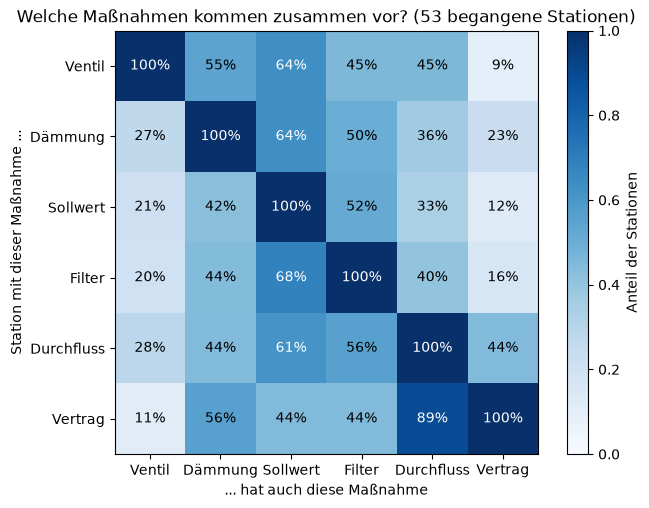

In [6]:
L0 = L.fillna(0).astype(int)
zusammen = pd.DataFrame({b: [(L0[a] * L0[b]).sum() / L0[a].sum() for a in mb.ZIELE] for b in mb.ZIELE}, index=mb.ZIELE)
zusammen = zusammen.rename(index=mb.ZIEL_TEXT, columns=mb.ZIEL_TEXT)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
bild = ax.imshow(zusammen, cmap="Blues", vmin=0, vmax=1)
for i in range(len(zusammen)):
    for j in range(len(zusammen)):
        wert = zusammen.iloc[i, j]
        ax.text(j, i, f"{wert:.0%}", ha="center", va="center", color="white" if wert > 0.6 else "black")
ax.set_xticks(range(len(zusammen)), zusammen.columns)
ax.set_yticks(range(len(zusammen)), zusammen.index)
ax.set_xlabel("... hat auch diese Maßnahme")
ax.set_ylabel("Station mit dieser Maßnahme ...")
ax.set_title("Welche Maßnahmen kommen zusammen vor? (53 begangene Stationen)")
fig.colorbar(bild, label="Anteil der Stationen")

In [7]:
fig.savefig(BILDER / "01_massnahmen_zusammen.png", bbox_inches="tight")

In [8]:
andere = L0.sum(axis=1) - L0["daemmung"]
pd.crosstab(andere.rename("andere Maßnahmen an der Station"),
            L0["daemmung"].map({0: "ohne Dämmung", 1: "mit Dämmung"}), margins=True, margins_name="Summe")

daemmung,mit Dämmung,ohne Dämmung,Summe
andere Maßnahmen an der Station,,,
0,3,5,8
1,5,6,11
2,6,15,21
3,5,4,9
4,3,1,4
Summe,22,31,53


Sollwert gesenkt (62 %) und Filter gereinigt (47 %) wurden bei jeder zweiten bis dritten Station gemacht. In jeder Zeile der Abbildung steht der Sollwert bei 40 bis 70 %, das sieht nach Routine einer Begehung aus, nicht nach einem gezielt gefundenen Fehler. Ein verkleinerter Vertrag kommt fast immer zusammen mit neu eingestelltem Durchfluss vor (8 von 9), was passt, denn wer den Vertrag verkleinert, stellt den Durchfluss neu ein. Die Dämmung (42 %) ist keine Restmaßnahme an Stationen, an denen sonst nichts zu tun war, sie kommt bei wenigen wie bei vielen anderen Maßnahmen vor. Bei Sollwert und Filter ist also schon das Label schwach. Ein Modell, das sie vorhersagen soll, lernt eher die Gewohnheiten der Begehung als einen Fehler.

## 4 · Wirkung der Maßnahmen

Wenn eine Maßnahme etwas bewirkt, muss sich danach die passende Größe ändern, beim Ventiltausch zum Beispiel der Durchfluss in Sommernächten. Ändert sich nichts, war entweder nichts kaputt, oder die Maßnahme wirkt in den Daten nicht. Dann kann auch kein Modell den Befund vorher erkennen.

Dabei stört das Wetter. Die meisten Begehungen waren im September 2024, danach kam der Winter, und ein roher Vergleich vorher gegen nachher misst vor allem das Wetter. Deshalb wird der Tagesverbrauch zerlegt:

> Tagesverbrauch = **Grundlast** + Steigung × Heizgrad + **Rest**, mit Heizgrad = max(0, 15 °C − Außentemperatur)

Die Grundlast ist der Teil, der nicht vom Wetter abhängt, also Warmwasser und Wärmeverluste. Ungedämmte Leitungen müssten sie erhöhen. Der Wetteranteil (Steigung × Heizgrad) wächst, je kälter es ist, und der Rest ist, was das Wetter nicht erklärt. Geglättet über 28 Tage ergibt er den Trend. Das ist eine Zerlegung wie STL, nur ist die „Saison“ hier die Außentemperatur und nicht das Datum, denn eine Kalender-Saison würde einen warmen Winter als Trend lesen.

Das Fenster vorher sind die 365 Tage bis zur Begehung, nachher beginnt es 14 Tage danach, wenn sich die Einstellungen gesetzt haben, und geht höchstens 365 Tage. Die Daten enden für die meisten Stationen im Juli 2025. Für Rücklauf und Durchfluss wird dieselbe Zerlegung an den Heiztagen bis 12 °C vorher gelernt und nachher abgezogen.

### 4a · Die Zerlegung an einer Station

Station 69527340 hatte nur einen Dämmungsbefund (Notebook 25, Abschnitt 6.3).

In [9]:
beispiel = 69527340
datum = labels.loc[beispiel, "erste_begehung"]
tb = T[T["zaehler"] == beispiel]
vor, nach = mb.fenster(tb, datum)
k_vor = mb.wetter_fit(vor, "energie_kwh")
k_nach = mb.wetter_fit(nach, "energie_kwh")
print("Begehung:", datum.date(), "| Maßnahmen:", [mb.ZIEL_TEXT[b] for b in mb.ZIELE if labels.loc[beispiel, b] == 1])
print(f"vorher:  Grundlast {k_vor[0]:5.1f} kWh/Tag, Steigung {k_vor[1]:.2f} kWh je Heizgrad")
print(f"nachher: Grundlast {k_nach[0]:5.1f} kWh/Tag, Steigung {k_nach[1]:.2f} kWh je Heizgrad")

Begehung: 2024-11-19 | Maßnahmen: ['Dämmung']
vorher:  Grundlast  10.0 kWh/Tag, Steigung 3.95 kWh je Heizgrad
nachher: Grundlast   9.0 kWh/Tag, Steigung 4.11 kWh je Heizgrad


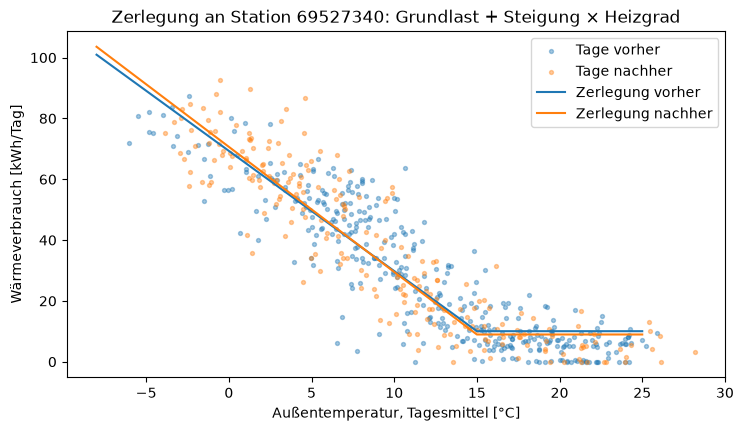

In [10]:
x = np.linspace(-8, 25, 100)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.scatter(vor["aussen"], vor["energie_kwh"], s=8, alpha=0.4, color="tab:blue")
ax.scatter(nach["aussen"], nach["energie_kwh"], s=8, alpha=0.4, color="tab:orange")
ax.plot(x, k_vor[0] + k_vor[1] * mb.heizgrad(x), color="tab:blue")
ax.plot(x, k_nach[0] + k_nach[1] * mb.heizgrad(x), color="tab:orange")
ax.set_title(f"Zerlegung an Station {beispiel}: Grundlast + Steigung × Heizgrad")
ax.set_xlabel("Außentemperatur, Tagesmittel [°C]")
ax.set_ylabel("Wärmeverbrauch [kWh/Tag]")
ax.legend(["Tage vorher", "Tage nachher", "Zerlegung vorher", "Zerlegung nachher"])

In [11]:
fig.savefig(BILDER / "02_zerlegung_beispiel.png", bbox_inches="tight")

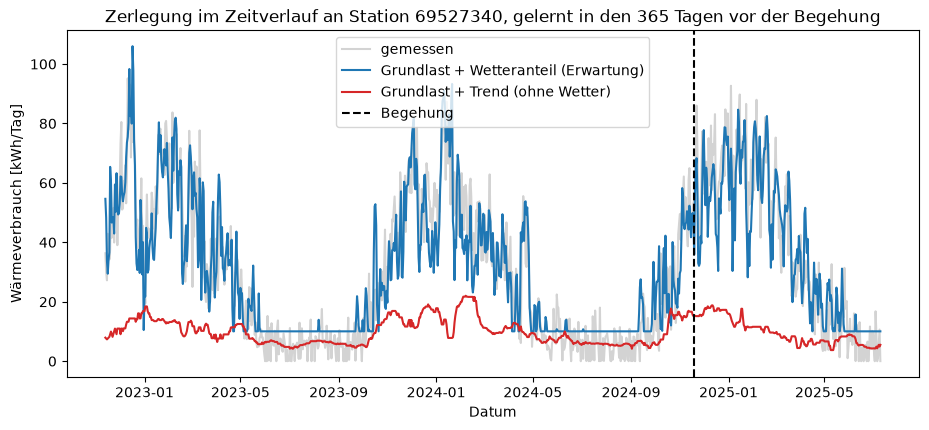

In [12]:
z = mb.zerlegung_verlauf(tb, datum)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(z.index, z["energie_kwh"], color="lightgray")
ax.plot(z.index, z["grundlast"] + z["wetteranteil"], color="tab:blue")
ax.plot(z.index, z["grundlast"] + z["trend"], color="tab:red")
ax.axvline(datum, color="black", linestyle="--")
ax.set_title(f"Zerlegung im Zeitverlauf an Station {beispiel}, gelernt in den 365 Tagen vor der Begehung")
ax.set_xlabel("Datum")
ax.set_ylabel("Wärmeverbrauch [kWh/Tag]")
ax.legend(["gemessen", "Grundlast + Wetteranteil (Erwartung)", "Grundlast + Trend (ohne Wetter)", "Begehung"])

In [13]:
fig.savefig(BILDER / "03_zerlegung_zeitverlauf.png", bbox_inches="tight")

An der Station mit nur einem Dämmungsbefund sinkt die Grundlast von 10,0 auf 9,0 kWh am Tag (−10 %), die Steigung bleibt fast gleich (3,95 und 4,11 kWh je Heizgrad). Im Zeitverlauf folgt die blaue Erwartung dem gemessenen Verbrauch gut. Der rote Trend schwankt aber mit der Jahreszeit, im Winter liegt er höher, die einfache Zerlegung erklärt das Wetter also nicht vollständig. Deshalb wird nie nur vorher gegen nachher an einer Station verglichen, sondern immer Stationen mit gegen Stationen ohne Maßnahme im selben Zeitraum. Was beide gemeinsam haben, fällt dann heraus.

### 4b · Wirkung an allen Stationen

Für jede begangene Station mit Datum werden die Größen aus dem Plan berechnet. Als Vergleich dienen die nie begangenen Stationen mit einem Stichtag in der Mitte der Begehungen. Sie zeigen, wie sich alles ohne Begehung verändert hat, durch Wetter, Netz und Zähler.

In [14]:
W = mb.wirkung(T, labels["erste_begehung"]).join(labels[mb.ZIELE])
nie = [z for z in T["zaehler"].unique() if z not in labels.index]
stichtag = labels["erste_begehung"].median()
W_nie = mb.wirkung(T[T["zaehler"].isin(nie)], pd.Series(stichtag, index=nie))
print("begangen mit Datum:", len(W), "| mit Werten nachher:", int(W["d_grundlast_rel"].notna().sum()))
print("nie begangen:", len(W_nie), "| Stichtag:", stichtag.date())
W[["tage_vor", "tage_nach", "d_nachtfluss_lph", "d_grundlast_rel", "d_ruecklauf_tag_k",
   "d_fluss_kalt_rel", "d_fluss_rel", "d_energie_rel", "d_kopplung"]].describe().round(2)

begangen mit Datum: 51 | mit Werten nachher: 45
nie begangen: 37 | Stichtag: 2024-09-20


,tage_vor,tage_nach,d_nachtfluss_lph,d_grundlast_rel,d_ruecklauf_tag_k,d_fluss_kalt_rel,d_fluss_rel,d_energie_rel,d_kopplung
count,51.00,51.00,44.00,45.00,45.00,44.00,45.00,45.00,44.00
mean,324.96,240.84,-33.59,0.03,-1.36,0.00,-0.04,-0.03,0.01
std,81.10,82.76,120.78,0.19,8.84,0.36,0.37,0.42,0.49
min,0.00,0.00,-557.00,-0.31,-26.41,-0.99,-1.15,-1.42,-1.33
25%,317.50,220.00,0.00,-0.09,-2.93,-0.15,-0.14,-0.15,-0.15
50%,365.00,274.00,0.00,-0.00,-0.15,0.00,-0.04,-0.06,-0.02
75%,365.00,285.00,0.00,0.11,0.93,0.12,0.15,0.06,0.09
max,365.00,351.00,168.50,0.65,36.97,1.42,1.16,1.40,1.51


In [15]:
zeilen = []
for b, (spalte, richtung, text) in mb.PLAN_WIRKUNG.items():
    teil = W if b == "ventil" else W[W["ventil"] != 1]
    r = mb.plan_pruefen(teil[spalte], teil[b], gruppen, richtung)
    zeilen.append({"Befund": mb.ZIEL_TEXT[b], "Größe": spalte, "erwartet": RICHTUNG_WIRKUNG[richtung], **r,
                   "Median nie begangen": W_nie[spalte].median()})
WT = pd.DataFrame(zeilen)
echt = WT["erwartet"] != RICHTUNG_WIRKUNG[0]
WT.loc[echt, "p nach Holm"] = mb.holm(WT.loc[echt, "p"])
WT.round(3)

,Befund,Größe,erwartet,Stationen,mit Befund,Median mit,Median ohne,AUC,unten,oben,p,Median nie begangen,p nach Holm
0,Ventil,d_nachtfluss_lph,sinkt,44,8,-61.500,0.000,0.809,0.559,0.994,0.001,0.000,0.004
1,Dämmung,d_grundlast_rel,sinkt,36,14,-0.021,-0.002,0.532,0.323,0.731,0.374,0.047,1.000
2,Sollwert,d_ruecklauf_tag_k,sinkt,36,24,-0.220,0.613,0.587,0.387,0.782,0.219,0.187,0.874
3,Filter,d_fluss_kalt_rel,steigt,35,17,0.020,0.006,0.490,0.289,0.687,0.548,0.019,1.000
4,Durchfluss,d_fluss_rel,sinkt,36,13,-0.024,-0.037,0.438,0.257,0.642,0.736,0.049,1.000
5,Vertrag,d_energie_rel,gleich (Placebo),24,7,-0.000,-0.090,0.613,0.304,0.905,0.407,0.028,NaN


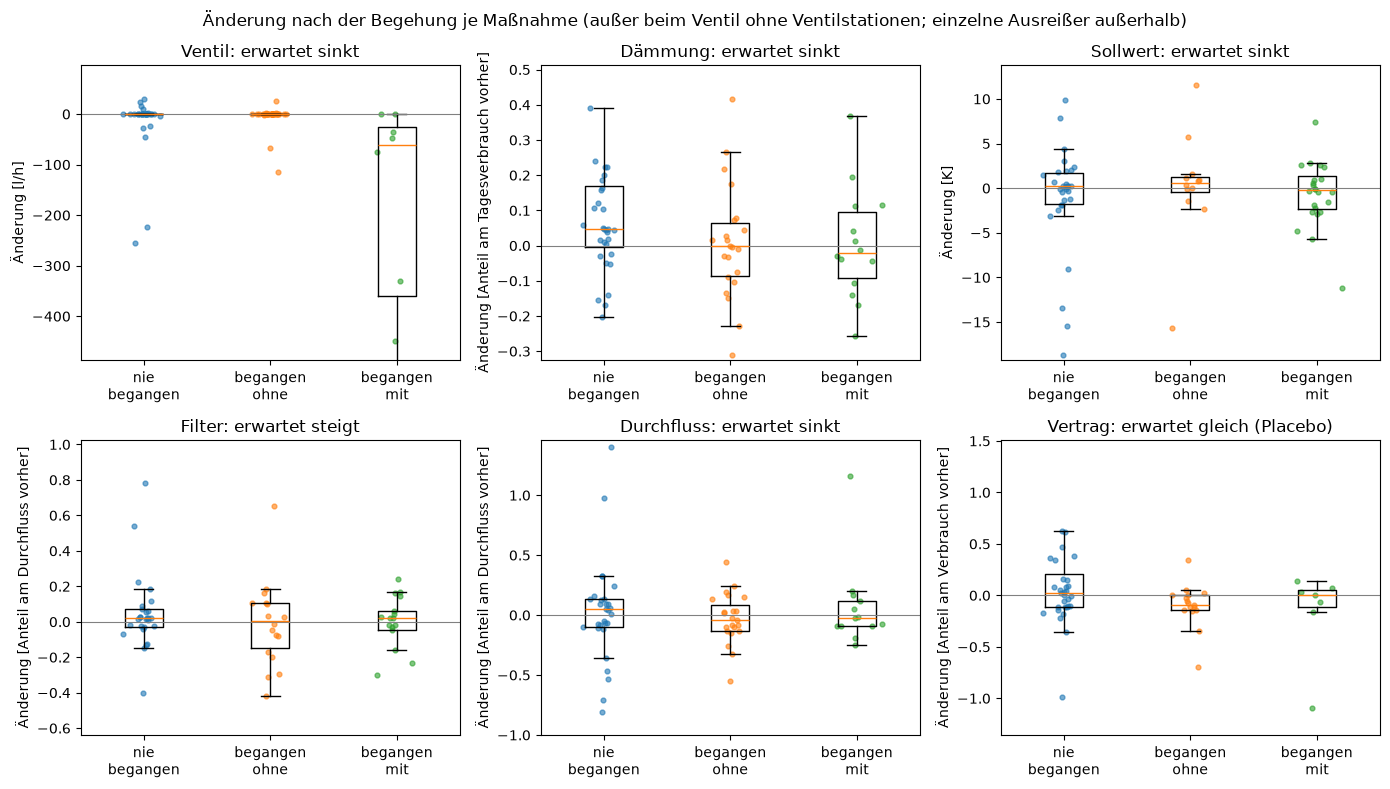

In [16]:
EINHEIT = {"d_nachtfluss_lph": "Änderung [l/h]", "d_grundlast_rel": "Änderung [Anteil am Tagesverbrauch vorher]",
           "d_ruecklauf_tag_k": "Änderung [K]", "d_fluss_kalt_rel": "Änderung [Anteil am Durchfluss vorher]",
           "d_fluss_rel": "Änderung [Anteil am Durchfluss vorher]", "d_energie_rel": "Änderung [Anteil am Verbrauch vorher]",
           "d_kopplung": "Änderung der Kopplung"}

fig, achsen = plt.subplots(2, 3, figsize=(14, 8))
for ax, (b, (spalte, richtung, text)) in zip(achsen.flat, mb.PLAN_WIRKUNG.items()):
    teil = W if b == "ventil" else W[W["ventil"] != 1]
    werte = [W_nie[spalte].dropna(), teil.loc[teil[b] == 0, spalte].dropna(), teil.loc[teil[b] == 1, spalte].dropna()]
    ax.boxplot(werte, showfliers=False)
    for i, w in enumerate(werte, start=1):
        ax.scatter(np.random.default_rng(i).normal(i, 0.06, len(w)), w, s=12, alpha=0.6)
    alle = pd.concat(werte)
    unten, oben = alle.quantile([0.03, 0.97])
    rand = 0.15 * (oben - unten)
    ax.set_ylim(unten - rand, oben + rand)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_xticks([1, 2, 3], ["nie\nbegangen", "begangen\nohne", "begangen\nmit"])
    ax.set_title(f"{mb.ZIEL_TEXT[b]}: erwartet {RICHTUNG_WIRKUNG[richtung]}")
    ax.set_ylabel(EINHEIT[spalte])
fig.suptitle("Änderung nach der Begehung je Maßnahme (außer beim Ventil ohne Ventilstationen; einzelne Ausreißer außerhalb)")
fig.tight_layout()

In [17]:
fig.savefig(BILDER / "04_wirkung_je_massnahme.png", bbox_inches="tight")

Beim Ventil ist die Wirkung klar messbar. Nach dem Tausch sinkt der Durchfluss in Sommernächten im Median um 62 l/h, bei den übrigen begangenen Stationen bleibt er bei 0 (AUC 0,81, nach Holm gesichert, p = 0,004). Beim Sollwert gibt es höchstens eine Andeutung, der Rücklauf tagsüber sinkt im Median um 0,2 K, bei den übrigen steigt er um 0,6 K (AUC 0,59, nicht gesichert). Notebook 25 (Abschnitt 6.3) hatte an einer Station 1 bis 3 K gesehen, über alle ist es weniger. Dämmung, Filter und Durchfluss zeigen keine messbare Wirkung (AUC 0,44 bis 0,53). Das Placebo Vertrag zeigt wie erwartet keine Wirkung (p = 0,41), das Verfahren erfindet also keine.

Nur der Ventiltausch hinterlässt damit eine klare Spur im Zähler. Bei Dämmung, Filter und Durchfluss ändert sich nichts, was über die normale Streuung hinausgeht. Entweder war dort nichts Nennenswertes kaputt, oder die Wirkung ist kleiner als das, was ein Wärmezähler im Alltag auflösen kann. In beiden Fällen kann kein Modell diese Befunde vorher sicher erkennen.

### 4c · Kontrolle: mit allen Stationen

Dieselben Tests, diesmal mit den Ventilstationen.

In [18]:
zeilen = []
for b, (spalte, richtung, text) in mb.PLAN_WIRKUNG.items():
    r = mb.plan_pruefen(W[spalte], W[b], gruppen, richtung)
    zeilen.append({"Befund": mb.ZIEL_TEXT[b], "AUC ohne Ventilstationen": WT.set_index("Befund").loc[mb.ZIEL_TEXT[b], "AUC"],
                   "AUC mit allen": r["AUC"], "Stationen": r["Stationen"], "mit Befund": r["mit Befund"], "p": r["p"]})
pd.DataFrame(zeilen).round(3)

,Befund,AUC ohne Ventilstationen,AUC mit allen,Stationen,mit Befund,p
0,Ventil,0.809,0.809,44,8,0.001
1,Dämmung,0.532,0.498,45,18,0.509
2,Sollwert,0.587,0.620,45,30,0.095
3,Filter,0.490,0.529,44,22,0.368
4,Durchfluss,0.438,0.498,45,17,0.510
5,Vertrag,0.613,0.613,29,8,0.369


Mit den Ventilstationen ändert sich das Bild nicht, der Sollwert liegt bei 0,62 (p = 0,10), Dämmung, Filter und Durchfluss um 0,5.

### 4d · Wie viele Labels zeigen eine Wirkung?

Für jede Maßnahme zählt, wie viele Stationen mit dieser Maßnahme sich deutlicher ändern als 80 % der begangenen Stationen ohne sie. Ohne jede Wirkung wären das zufällig etwa 20 %.

In [19]:
zeilen = []
for b, (spalte, richtung, text) in mb.PLAN_WIRKUNG.items():
    if richtung == 0:
        continue
    teil = W if b == "ventil" else W[W["ventil"] != 1]
    ohne = teil.loc[teil[b] == 0, spalte].dropna()
    mit = teil.loc[teil[b] == 1, spalte].dropna()
    grenze_ohne = ohne.quantile(0.2 if richtung < 0 else 0.8)
    deutlich = mit < grenze_ohne if richtung < 0 else mit > grenze_ohne
    zeilen.append({"Befund": mb.ZIEL_TEXT[b], "Stationen mit Maßnahme": len(mit), "deutliche Wirkung": int(deutlich.sum()),
                   "Anteil": round(deutlich.mean(), 2), "ohne Wirkung zufällig": 0.2})
WA = pd.DataFrame(zeilen)
WA

,Befund,Stationen mit Maßnahme,deutliche Wirkung,Anteil,ohne Wirkung zufällig
0,Ventil,8,6,0.75,0.2
1,Dämmung,14,4,0.29,0.2
2,Sollwert,24,9,0.38,0.2
3,Filter,17,4,0.24,0.2
4,Durchfluss,13,2,0.15,0.2


Beim Ventil zeigen 6 von 8 Stationen eine deutliche Wirkung, fast viermal so viele wie ohne Wirkung zu erwarten. Beim Sollwert sind es 9 von 24 (38 %), knapp doppelt so viele. Bei Dämmung (29 %), Filter (24 %) und Durchfluss (15 %) liegt der Anteil bei den 20 %, die man ganz ohne Wirkung erwartet. Für bessere Labels hieße das, nur die Maßnahmen als Befund zu zählen, die eine messbare Wirkung hatten. Beim Ventil ginge das schon heute, bei den anderen bliebe kaum etwas übrig.

## 5 · Zeitstruktur

### 5a · Gleitende Korrelation

Für jedes Fenster von 14 Tagen wird die Korrelation zwischen dem Durchfluss am Tag und der Außentemperatur berechnet und mit −1 malgenommen. 1 heißt, je kälter, desto mehr Wasser, so soll es sein. 0 heißt, der Durchfluss hat mit dem Wetter nichts zu tun, und unter 0 heißt verkehrt herum. Gerechnet wird nur in der Heizzeit, sonst ist die Korrelation bedeutungslos. Als Beispiel dient Station 68956351, an der am 09.09.2024 das Ventil getauscht wurde (Fall 1 aus Notebook 35).

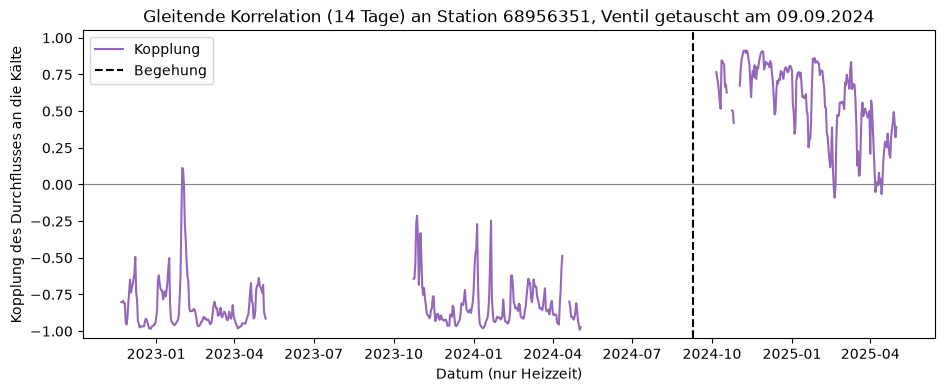

In [20]:
beispiel_v = 68956351
datum_v = labels.loc[beispiel_v, "erste_begehung"]
kp = mb.kopplung_verlauf(T[T["zaehler"] == beispiel_v])

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(kp.index, kp, color="tab:purple")
ax.axvline(datum_v, color="black", linestyle="--")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylim(-1.05, 1.05)
ax.set_title(f"Gleitende Korrelation (14 Tage) an Station {beispiel_v}, Ventil getauscht am {datum_v:%d.%m.%Y}")
ax.set_xlabel("Datum (nur Heizzeit)")
ax.set_ylabel("Kopplung des Durchflusses an die Kälte")
ax.legend(["Kopplung", "Begehung"])

In [21]:
fig.savefig(BILDER / "05_kopplung_beispiel.png", bbox_inches="tight")

Die Zusatzprüfung aus dem Plan fragt, ob die Kopplung nach einem Ventiltausch besser wird als bei begangenen Stationen ohne Ventiltausch.

In [22]:
spalte, richtung, text = mb.PLAN_ZUSATZ["ventil"]
ZT = pd.DataFrame([{"Befund": "Ventil (Zusatz)", "Größe": spalte, "erwartet": RICHTUNG_WIRKUNG[richtung],
                    **mb.plan_pruefen(W[spalte], W["ventil"], gruppen, richtung),
                    "Median nie begangen": W_nie[spalte].median()}])
ZT.round(3)

,Befund,Größe,erwartet,Stationen,mit Befund,Median mit,Median ohne,AUC,unten,oben,p,Median nie begangen
0,Ventil (Zusatz),d_kopplung,steigt,44,9,-0.02,-0.015,0.495,0.256,0.73,0.526,-0.015


An Station 68956351 dreht sich die Kopplung um. Vorher liegt sie fast bei −1, das kaputte Ventil ließ an warmen Tagen mehr Wasser durch als an kalten, danach bei etwa +0,75, wie es sein soll. Über alle Ventilstationen zeigt sich das aber nicht (AUC 0,50). Diese eine Station hatte das verkehrte Muster im Winter, die meisten offenen Ventile fallen dagegen im Sommer nachts auf, wenn kein Bedarf ist (Abschnitt 4b). Auch als Kennzahl vor der Begehung trennt die Kopplung die Ventile nicht (6b). Die gleitende Korrelation ist also ein gutes Bild für einen Einzelfall, aber kein Erkennungsmerkmal.

### 5b · Zerlegung im Zeitverlauf: Dämmung

Der Trend aus Abschnitt 4 wird für alle begangenen Stationen ohne Ventilbefund am Tag der Begehung ausgerichtet, die Zerlegung wurde in den 365 Tagen davor gelernt. Was beide Gruppen gemeinsam haben, also das Jahresmuster, das die einfache Zerlegung nicht erklärt, Wetter und Netz, zeigt sich in beiden Linien. Entscheidend ist der Abstand zwischen den Linien nach der Begehung. Liegt die grüne Linie dann tiefer, hat die Dämmung den Verbrauch bei gleichem Wetter gesenkt.

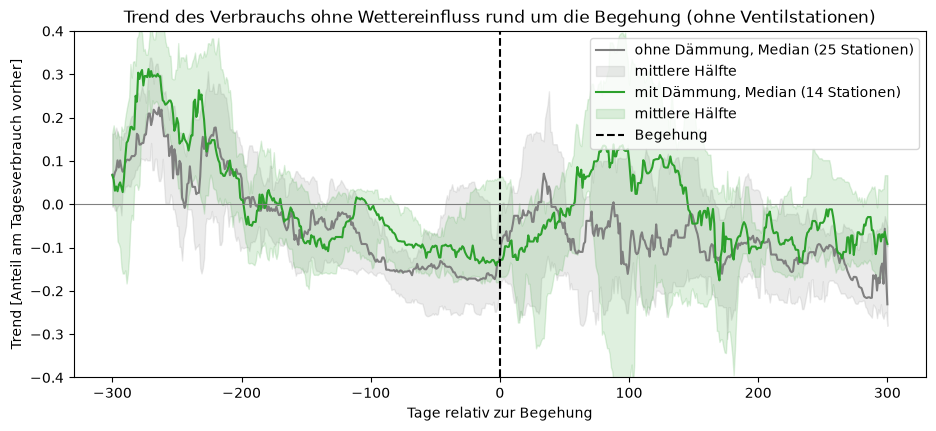

In [23]:
EV = mb.ereignisverlauf(T, labels["erste_begehung"]).join(labels[["ventil", "daemmung"]], on="zaehler")
EV = EV[EV["ventil"] != 1].astype({"daemmung": int})
n = EV.groupby("daemmung")["zaehler"].nunique()

fig, ax = plt.subplots(figsize=(11, 4.5))
for wert, farbe in ((0, "tab:gray"), (1, "tab:green")):
    g = EV[EV["daemmung"] == wert].groupby("tag_rel")["trend_rel"]
    mitte = g.median()
    ax.plot(mitte.index, mitte, color=farbe)
    ax.fill_between(mitte.index, g.quantile(0.25), g.quantile(0.75), color=farbe, alpha=0.15)
ax.axvline(0, color="black", linestyle="--")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylim(-0.4, 0.4)
ax.set_title("Trend des Verbrauchs ohne Wettereinfluss rund um die Begehung (ohne Ventilstationen)")
ax.set_xlabel("Tage relativ zur Begehung")
ax.set_ylabel("Trend [Anteil am Tagesverbrauch vorher]")
ax.legend([f"ohne Dämmung, Median ({n.get(0, 0)} Stationen)", "mittlere Hälfte",
           f"mit Dämmung, Median ({n.get(1, 0)} Stationen)", "mittlere Hälfte", "Begehung"])

In [24]:
fig.savefig(BILDER / "06_trend_daemmung.png", bbox_inches="tight")

Beide Linien folgen demselben Muster, vor der Begehung einem gemeinsamen Jahresmuster, das die einfache Zerlegung nicht erklärt, und danach ähnlichen Schwankungen. Nach der Begehung liegt die grüne Linie nicht tiefer als die graue, zeitweise sogar höher. Das passt zu 4b, am Verbrauch sieht man die Dämmung nicht.

## 6 · Neue Kennzahlen

Je Befund gibt es eine neue Kennzahl, nur aus Daten vor der Begehung (Winter 23/24 und Sommer 2024, wie in Notebook 25):

| Kennzahl | So wird sie berechnet |
|---|---|
| `kopplung_fluss_winter` | Median der gleitenden Korrelation aus 5a im Winter 23/24 |
| `abkuehlrate_stillstand` | Sommer 2024, Stunden ohne Durchfluss: Um welchen Anteil des Abstands zu 20 °C kühlt der Vorlauf je Stunde ab? (Newton) |
| `ruecklauf_schwachlast` | Winter, Stunden unter 20 % der Spitzenleistung: Median des Rücklaufs |
| `fluss_saettigung` | Winter: Durchfluss-Spitze an Tagen bis 1 °C geteilt durch die Fortschreibung der Geraden aus milden Tagen (3 bis 12 °C) |
| `fluss_plateau_anteil` | Winter: Anteil der Stunden mit Durchfluss, die bei mindestens 95 % des 99-%-Werts liegen |
| `volllaststunden` | Wärme der 365 Tage vor der Begehung geteilt durch den alten Vertrag |
| `grundlast_anteil` (zusätzlich) | Grundlast aus der Zerlegung geteilt durch den mittleren Tagesverbrauch |
| `kopplung_energie_winter` (zusätzlich) | wie die Kopplung, aber mit dem Wärmeverbrauch statt dem Durchfluss |

Die beiden letzten gehören zu keinem Befund im Plan und stehen nur in der Übersicht 6d.

In [25]:
grenze = fk.grenze_vor_begehung(labels, e["stunden"]["zaehler"].unique())
NK = mb.neue_kennzahlen(e["stunden"], T, grenze, labels["vertrag_alt_kw"])
kz = fv.kennzahlen_vor_begehung(e["stunden"], labels)
print("fehlend bei den 53 Stationen:", NK.reindex(ids).isna().sum().to_dict())
NK.reindex(ids).describe().T.round(3)

fehlend bei den 53 Stationen: {'kopplung_fluss_winter': 0, 'kopplung_energie_winter': 0, 'abkuehlrate_stillstand': 12, 'fluss_saettigung': 0, 'fluss_plateau_anteil': 0, 'ruecklauf_schwachlast': 3, 'volllaststunden': 23, 'grundlast_anteil': 0}


,count,mean,std,min,25%,50%,75%,max
kopplung_fluss_winter,53.0,0.393,0.454,-0.869,0.315,0.502,0.666,0.909
kopplung_energie_winter,53.0,0.473,0.238,-0.646,0.401,0.516,0.577,0.911
abkuehlrate_stillstand,41.0,0.198,0.085,-0.048,0.164,0.196,0.246,0.395
fluss_saettigung,53.0,1.035,0.286,0.646,0.886,0.960,1.105,2.096
fluss_plateau_anteil,53.0,0.046,0.069,0.011,0.017,0.021,0.034,0.371
ruecklauf_schwachlast,50.0,44.945,15.385,25.000,33.200,39.400,54.475,75.600
volllaststunden,30.0,1369.669,509.809,541.897,1059.587,1362.230,1593.664,2867.455
grundlast_anteil,53.0,0.355,0.129,0.052,0.276,0.354,0.439,0.730


### 6a · Neue Information oder nur alte Kennzahl in neuem Gewand?

Die Rangkorrelation jeder neuen Kennzahl mit der ähnlichsten der 12 Kennzahlen aus Notebook 35 zeigt das. Werte nahe ±1 heißen, dass nichts Neues dazukommt.

In [26]:
rho = NK.join(kz[fv.KENNZAHLEN]).reindex(ids).corr(method="spearman").loc[NK.columns, fv.KENNZAHLEN]
naechste = rho.abs().idxmax(axis=1)
pd.DataFrame({"ähnlichste alte Kennzahl": naechste,
              "Rangkorrelation": [rho.loc[k, naechste[k]] for k in rho.index]}).round(2)

,ähnlichste alte Kennzahl,Rangkorrelation
kopplung_fluss_winter,winter_fluss_cv,0.45
kopplung_energie_winter,anteil_volumenstrom,0.34
abkuehlrate_stillstand,winter_fluss_cv,0.40
fluss_saettigung,ruecklauf_lastgewichtet,-0.35
fluss_plateau_anteil,ruecklauf_lastgewichtet,0.45
ruecklauf_schwachlast,sommer_nachtfluss_lph,0.70
volllaststunden,sommer_nacht_spreizung_k,0.32
grundlast_anteil,sommerlast_anteil,0.74


Die meisten neuen Kennzahlen bringen neue Information (Rangkorrelation höchstens 0,45). Zwei ähneln alten, `grundlast_anteil` der `sommerlast_anteil` (0,74, beide messen den wetterunabhängigen Anteil) und `ruecklauf_schwachlast` dem `sommer_nachtfluss_lph` (0,70). Wo nachts im Sommer Wasser fließt, ist auch der Rücklauf bei Schwachlast warm, das ist das offene Ventil.

### 6b · Jede neue Kennzahl mit ihrem Befund

Zum Vergleich stehen daneben die einfache Kennzahl der Messlatte aus Notebook 25 und die beste an den Befunden angepasste Regel aus Notebook 35 (Abschnitt 18). Die Messlatte lief auf einer etwas anderen Stationsauswahl, ihre Zahl ist nur eine Orientierung.

In [27]:
MESSLATTE_25 = {"ventil": 0.88, "daemmung": 0.64, "temperatur": 0.60, "filter": 0.36, "durchfluss": 0.50, "ueberdimensioniert": 0.78}
kg = pd.read_csv(fv.AUSGABE / "ki_gegen_regel.csv").set_index("Fehlerart")

zeilen = []
for b, (spalte, richtung, text) in mb.PLAN_KENNZAHLEN.items():
    r = mb.plan_pruefen(NK.reindex(ids)[spalte], labels.reindex(ids)[b], gruppen, richtung)
    zeilen.append({"Befund": mb.ZIEL_TEXT[b], "Kennzahl": spalte, "bei Befund": RICHTUNG_KENNZAHL[richtung], **r,
                   "Messlatte NB 25": MESSLATTE_25[b], "Regel angepasst (NB 35)": kg.loc[b, "Regel angepasst"]})
KT = pd.DataFrame(zeilen)
KT["p nach Holm"] = mb.holm(KT["p"])
KT.round(3)

,Befund,Kennzahl,bei Befund,Stationen,mit Befund,Median mit,Median ohne,AUC,unten,oben,p,Lernpfad B,Regel angepasst (NB 34),p nach Holm
0,Ventil,kopplung_fluss_winter,niedriger,53,11,0.564,0.484,0.522,0.284,0.760,0.412,0.88,0.794,0.650
1,Dämmung,abkuehlrate_stillstand,höher,41,15,0.232,0.185,0.685,0.493,0.868,0.023,0.64,0.607,0.139
2,Sollwert,ruecklauf_schwachlast,höher,50,31,43.000,38.500,0.543,0.380,0.715,0.310,0.60,0.511,0.650
3,Filter,fluss_saettigung,niedriger,53,25,0.935,0.982,0.620,0.466,0.771,0.067,0.36,0.474,0.337
4,Durchfluss,fluss_plateau_anteil,niedriger,53,18,0.018,0.022,0.565,0.404,0.731,0.217,0.50,0.377,0.650
5,Vertrag,volllaststunden,niedriger,30,9,1257.846,1364.048,0.624,0.375,0.837,0.150,0.78,0.650,0.600


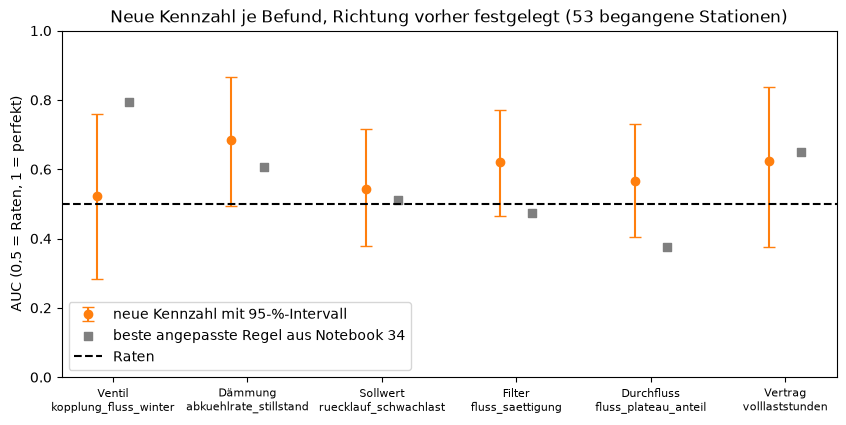

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.5))
pos = np.arange(len(KT))
balken = ax.errorbar(pos - 0.12, KT["AUC"], yerr=[KT["AUC"] - KT["unten"], KT["oben"] - KT["AUC"]], fmt="o", color="tab:orange", capsize=4)
punkte = ax.scatter(pos + 0.12, KT["Regel angepasst (NB 35)"], marker="s", color="tab:gray")
raten = ax.axhline(0.5, color="black", linestyle="--")
ax.set_xticks(pos, [f"{b}\n{k}" for b, k in zip(KT["Befund"], KT["Kennzahl"])], fontsize=8)
ax.set_ylim(0, 1)
ax.set_title("Neue Kennzahl je Befund, Richtung vorher festgelegt (53 begangene Stationen)")
ax.set_xlabel("")
ax.set_ylabel("AUC (0,5 = Raten, 1 = perfekt)")
ax.legend([balken, punkte, raten], ["neue Kennzahl mit 95-%-Intervall", "beste angepasste Regel aus Notebook 35", "Raten"])

In [29]:
fig.savefig(BILDER / "07_neue_kennzahlen.png", bbox_inches="tight")

Bei der Dämmung kommt die Abkühlrate auf 0,69, in die vorher festgelegte Richtung. Gedämmte Stationen kühlten vorher schneller ab (Median 0,23 gegen 0,19 je Stunde), ohne Korrektur mit p = 0,02, nach Holm mit 0,14, also nicht gesichert. Sie ist besser als die beste angepasste Regel aus Notebook 35 (0,61) und die erste Kennzahl, die die Dämmung mit einer physikalischen Begründung erkennt. Beim Filter geht die Sättigung mit 0,62 zum ersten Mal in die vermutete Richtung (Messlatte Notebook 25: 0,36), aber nicht gesichert (p = 0,07, nach Holm 0,34). Sollwert (0,54), Durchfluss (0,57), Vertrag (0,62) und Ventil (0,52) sind nicht nennenswert besser als Raten. Für den Vertrag bleibt die Auslastung zum alten Vertrag besser (Messlatte Notebook 25: 0,78, Notebook 35: 0,65 bis 0,76). Nach Holm ist keine neue Kennzahl gesichert, und die Abkühlrate ist der einzige Kandidat, der eine Nachprüfung lohnt.

### 6c · Nachprüfung: Kühlt das Wasser nach dem Dämmen langsamer ab?

Diese Prüfung stand nicht im Plan. Sie kam dazu, nachdem die Abkühlrate in 6b bei der Dämmung in die erwartete Richtung ging, und steht in `PLAN_NACHTRAG`. Die Richtung ist durch die Physik eindeutig: Eine gedämmte Leitung verliert weniger Wärme, also muss stehendes Wasser danach langsamer abkühlen. Wenn das stimmt, misst die Abkühlrate wirklich die Dämmung und nicht irgendetwas, das zufällig mit ihr zusammenhängt. Verglichen wird der Sommer 2024 vor der Begehung mit dem Sommer 2025, nur an Stationen mit Begehung bis April 2025 und ohne Ventilbefund, weil ein getauschtes Ventil den Stillstand selbst ändert.

In [30]:
A = mb.abkuehlrate_vorher_nachher(e["stunden"], labels["erste_begehung"]).join(labels[["ventil", "daemmung"]])
A2 = A[A["ventil"] != 1].dropna(subset=["d_abkuehlrate"]).astype({"daemmung": int})
spalte, richtung, text = mb.PLAN_NACHTRAG["daemmung"]
NT = pd.DataFrame([{"Befund": "Dämmung (Nachtrag)", "Größe": spalte, "erwartet": RICHTUNG_WIRKUNG[richtung],
                    **mb.plan_pruefen(A2[spalte], A2["daemmung"], gruppen, richtung)}])
print("Stationen mit Abkühlrate vorher und nachher:", len(A2), "| davon gedämmt:", int(A2["daemmung"].sum()))
NT.round(4)

Stationen mit Abkühlrate vorher und nachher: 28 | davon gedämmt: 10


,Befund,Größe,erwartet,Stationen,mit Befund,Median mit,Median ohne,AUC,unten,oben,p
0,Dämmung (Nachtrag),d_abkuehlrate,sinkt,28,10,-0.0497,0.0078,0.8278,0.5913,1.0,0.0016


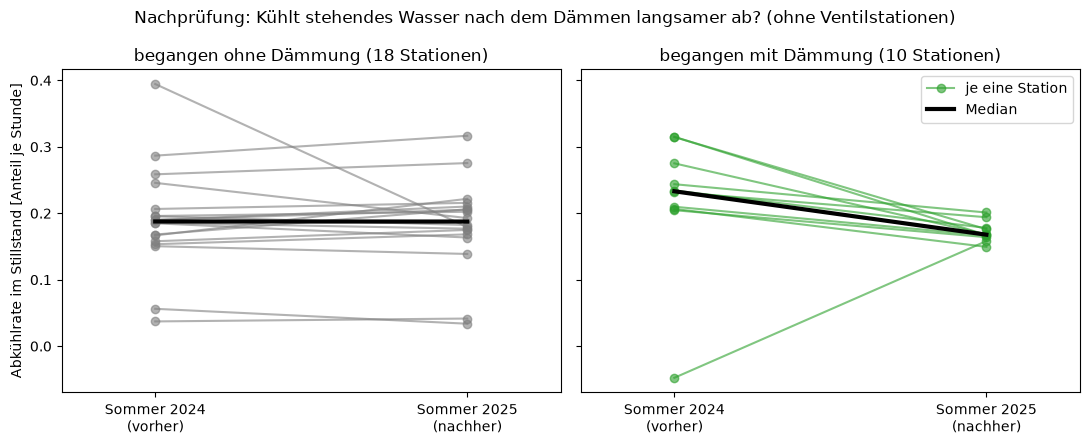

In [31]:
fig, achsen = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, wert, farbe, titel in ((achsen[0], 0, "tab:gray", "begangen ohne Dämmung"), (achsen[1], 1, "tab:green", "begangen mit Dämmung")):
    teil = A2[A2["daemmung"] == wert]
    for _, zeile in teil.iterrows():
        ax.plot([0, 1], [zeile["abkuehlrate_vor"], zeile["abkuehlrate_nach"]], color=farbe, alpha=0.6, marker="o")
    ax.plot([0, 1], [teil["abkuehlrate_vor"].median(), teil["abkuehlrate_nach"].median()], color="black", linewidth=3)
    ax.set_xticks([0, 1], ["Sommer 2024\n(vorher)", "Sommer 2025\n(nachher)"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_title(f"{titel} ({len(teil)} Stationen)")
    ax.set_xlabel("")
achsen[0].set_ylabel("Abkühlrate im Stillstand [Anteil je Stunde]")
linien = achsen[1].get_lines()
achsen[1].legend([linien[0], linien[-1]], ["je eine Station", "Median"])
fig.suptitle("Nachprüfung: Kühlt stehendes Wasser nach dem Dämmen langsamer ab? (ohne Ventilstationen)")
fig.tight_layout()

In [32]:
fig.savefig(BILDER / "08_abkuehlrate_vorher_nachher.png", bbox_inches="tight")

Bei 9 von 10 gedämmten Stationen kühlt stehendes Wasser im Sommer 2025 langsamer ab als im Sommer 2024, im Median um 0,05 je Stunde. Bei den Stationen ohne Dämmung ändert sich im Median nichts (+0,01). Das ergibt eine AUC von 0,83 bei p = 0,002.

Dahinter könnte eine Rückkehr zur Mitte stecken. Gedämmte Stationen lagen vorher höher, und wer vorher hoch lag, sinkt oft auch ohne Maßnahme wieder, weil ein Teil der hohen Messung Zufall war. Deshalb wird der Unterschied bei gleichem Ausgangswert geschätzt, mit der Regression Änderung = a + b · vorher + c · gedämmt. Eine gedämmte Station hat vorher einen unmöglichen Wert, bei dem das Wasser im Stillstand angeblich wärmer wurde. Gerechnet wird mit und ohne sie.

In [33]:
zeilen = [{"Variante": "alle Stationen", **mb.effekt_bei_gleichem_start(A2, "d_abkuehlrate", "abkuehlrate_vor", "daemmung")},
          {"Variante": "ohne unmöglichen Ausgangswert (unter 0)",
           **mb.effekt_bei_gleichem_start(A2[A2["abkuehlrate_vor"] > 0], "d_abkuehlrate", "abkuehlrate_vor", "daemmung")}]
hoch = A2[A2["abkuehlrate_vor"] >= 0.2].groupby("daemmung")["d_abkuehlrate"].agg(["count", "median"])
print("Nur Stationen, die vorher mindestens 0,2 hatten:")
print(hoch.rename(index={0: "ohne Dämmung", 1: "mit Dämmung"}).round(3))
RM = pd.DataFrame(zeilen)
RM.round(3)

Nur Stationen, die vorher mindestens 0,2 hatten:
              count  median
daemmung                   
ohne Dämmung      5   0.009
mit Dämmung       9  -0.056


,Variante,Stationen,Effekt,unten,oben,unter 0 in
0,alle Stationen,28,-0.021,-0.081,0.010,0.923
1,ohne unmöglichen Ausgangswert (unter 0),27,-0.040,-0.090,-0.007,0.994


Bei gleichem Ausgangswert bleibt ein Effekt von −0,02 mit allen Stationen und −0,04 ohne die Station mit dem unmöglichen Ausgangswert. Gesichert ist er nur ohne diese Station (Intervall −0,09 bis −0,01). Unter den Stationen, die vorher mindestens 0,2 hatten, sinkt die Rate bei den gedämmten im Median um 0,06, bei den übrigen nicht (+0,01).

Die Abkühlrate ist damit der erste Hinweis, dass das Dämmungs-Label physikalisch etwas misst. Ungedämmte Leitungen kühlen schneller ab, nach dem Dämmen langsamer. Die Prüfung ist aber nachträglich ergänzt, es gibt nur 10 gedämmte Stationen, und ob sie gesichert ist, hängt an einem fragwürdigen Messwert. Das ist ein Hinweis, der an neuen Daten bestätigt werden muss, zum Beispiel im nächsten Sommer.

### 6d · Übersicht: jede neue Kennzahl gegen jeden Befund (nur zur Orientierung)

Vorsicht, das sind 48 Vergleiche ohne festgelegte Richtung. Bei so vielen Vergleichen sind einige Werte unter 0,35 oder über 0,65 allein durch Zufall zu erwarten. Was hier auffällt, ist eine Idee für eine neue Prüfung an neuen Daten, kein Ergebnis. Die AUC heißt hier immer „höherer Wert = Befund“, 0,3 hieße also niedriger bei Befund.

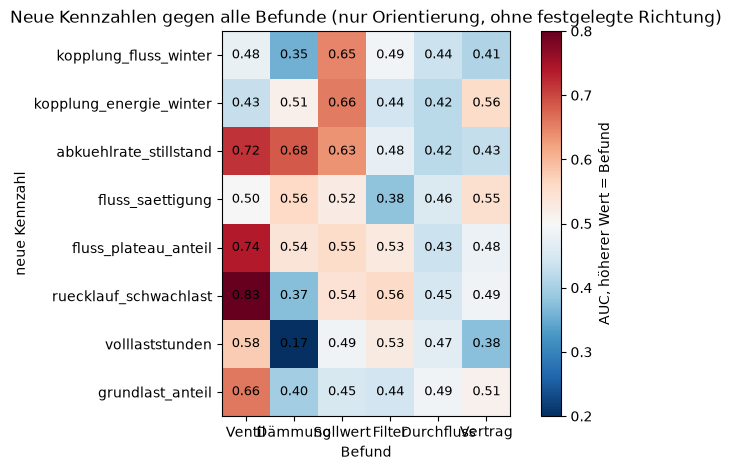

In [34]:
uebersicht = pd.DataFrame(index=NK.columns, columns=mb.ZIELE, dtype=float)
for b in mb.ZIELE:
    y = labels.reindex(ids)[b]
    for k in NK.columns:
        d = pd.DataFrame({"x": NK.reindex(ids)[k], "y": y}).dropna()
        if d["y"].nunique() == 2:
            uebersicht.loc[k, b] = roc_auc_score(d["y"].astype(int), d["x"])
uebersicht = uebersicht.rename(columns=mb.ZIEL_TEXT)

fig, ax = plt.subplots(figsize=(8, 5))
bild = ax.imshow(uebersicht.astype(float), cmap="RdBu_r", vmin=0.2, vmax=0.8)
for i in range(uebersicht.shape[0]):
    for j in range(uebersicht.shape[1]):
        ax.text(j, i, f"{uebersicht.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(uebersicht.shape[1]), uebersicht.columns)
ax.set_yticks(range(uebersicht.shape[0]), uebersicht.index)
ax.set_title("Neue Kennzahlen gegen alle Befunde (nur Orientierung, ohne festgelegte Richtung)")
ax.set_xlabel("Befund")
ax.set_ylabel("neue Kennzahl")
fig.colorbar(bild, label="AUC, höherer Wert = Befund")

In [35]:
fig.savefig(BILDER / "09_uebersicht_explorativ.png", bbox_inches="tight")

Was auffällt, taugt nur als Idee für spätere Prüfungen. Beim Ventil sprechen mehrere neue Kennzahlen an, am stärksten der Rücklauf bei Schwachlast (0,83), aber das Ventil erkennen die alten Sommerkennzahlen schon. Bei der Dämmung fallen die Volllaststunden auf (0,17, gedämmte Stationen haben also weniger Volllaststunden), mehr dazu in 6f. Beim Sollwert liegen beide Kopplungen bei 0,65, Stationen mit gesenktem Sollwert folgten der Außentemperatur also enger.

### 6e · Hilft es der KI?

Dieselbe logistische Regression wie in Notebook 35, mit dem Raster nur im Lernteil gesucht und denselben fünf Durchgängen, läuft einmal mit den 12 Kennzahlen und einmal mit den 12 plus den 6 neuen aus dem Plan. Vorher wird abgeglichen, ob dieser Code mit den 12 Kennzahlen genau dasselbe rechnet wie Notebook 35.

In [36]:
X = kz.join(NK)
nb35 = oof[(oof["kandidat"] == "LR Kennzahlen")].pivot_table(index="zaehler", columns="ziel", values="p")
abweichung = {}
P_ALT, P_NEU = {}, {}
for b in mb.ZIELE:
    P_ALT[b] = mb.lr_oof(X, oof, gruppen, b, "LR Kennzahlen", fv.KENNZAHLEN)
    abweichung[mb.ZIEL_TEXT[b]] = float((P_ALT[b] - nb35[b].reindex(P_ALT[b].index)).abs().max())
print("größte Abweichung zu Notebook 35 je Befund:", {k: round(v, 6) for k, v in abweichung.items()})

größte Abweichung zu Notebook 34 je Befund: {'Ventil': 0.0, 'Dämmung': 0.0, 'Sollwert': 0.0, 'Filter': 0.0, 'Durchfluss': 0.0, 'Vertrag': 0.0}


In [37]:
zeilen = []
for b in mb.ZIELE:
    P_NEU[b] = mb.lr_oof(X, oof, gruppen, b, "LR Kennzahlen + neue", fv.KENNZAHLEN + mb.NEUE_KENNZAHLEN)
    _, y = mb.folds_aus_oof(oof, b)
    g = gruppen.reindex(P_ALT[b].index).to_numpy()
    d, werte = fv.bootstrap_auc_differenzen(y, P_NEU[b].to_numpy(), P_ALT[b].to_numpy(), g)
    zeilen.append({"Befund": mb.ZIEL_TEXT[b], "Stationen": len(y), "mit Befund": int(y.sum()),
                   "AUC 12 Kennzahlen": roc_auc_score(y, P_ALT[b]), "AUC 12 + 6 neue": roc_auc_score(y, P_NEU[b]),
                   "Differenz": d, "unten": np.quantile(werte, 0.025), "oben": np.quantile(werte, 0.975),
                   "neu vorn in": (werte > 0).mean()})
RT = pd.DataFrame(zeilen)
RT.round(3)

,Befund,Stationen,mit Befund,AUC 12 Kennzahlen,AUC 12 + 6 neue,Differenz,unten,oben,neu vorn in
0,Ventil,53,11,0.816,0.825,0.009,-0.107,0.116,0.571
1,Dämmung,53,22,0.735,0.893,0.158,0.062,0.277,1.000
2,Sollwert,53,33,0.377,0.420,0.042,-0.090,0.176,0.739
3,Filter,53,25,0.426,0.371,-0.054,-0.173,0.067,0.192
4,Durchfluss,53,18,0.317,0.357,0.040,-0.098,0.188,0.692
5,Vertrag,35,9,0.393,0.333,-0.060,-0.286,0.146,0.276


Der Abgleich stimmt, mit den 12 Kennzahlen rechnet der Code genau wie Notebook 35 (Abweichung 0). Mit den 6 neuen Kennzahlen steigt die Dämmung von 0,74 auf 0,89 (+0,16, Intervall +0,06 bis +0,28). Bei allen anderen Befunden gibt es keinen gesicherten Unterschied, und Sollwert, Filter und Durchfluss bleiben unter 0,5. Ein Sprung dieser Größe bei der Dämmung wäre ein großes Ergebnis, deshalb wird er in 6f auseinandergenommen.

### 6f · Woher kommt der Zugewinn bei der Dämmung?

Ein Zugewinn dieser Größe muss auseinandergenommen werden, bevor man ihm traut. Zuerst wird geklärt, welche der sechs neuen Kennzahlen ihn trägt. Dafür kommt jede einzeln zu den 12 dazu, und jede wird einzeln aus den 18 weggelassen.

In [38]:
_, y_d = mb.folds_aus_oof(oof, "daemmung")
zeilen = []
for k in mb.NEUE_KENNZAHLEN:
    mit = mb.lr_oof(X, oof, gruppen, "daemmung", "LR 12 + eine", fv.KENNZAHLEN + [k])
    ohne = mb.lr_oof(X, oof, gruppen, "daemmung", "LR 18 ohne eine", fv.KENNZAHLEN + [n for n in mb.NEUE_KENNZAHLEN if n != k])
    zeilen.append({"neue Kennzahl": k, "fehlt bei Stationen": int(NK.reindex(ids)[k].isna().sum()),
                   "AUC 12 + nur diese": roc_auc_score(y_d, mit), "AUC 18 ohne diese": roc_auc_score(y_d, ohne)})
ZG = pd.DataFrame(zeilen)
print(f"Zum Vergleich: 12 Kennzahlen {roc_auc_score(y_d, P_ALT['daemmung']):.3f}, alle 18 {roc_auc_score(y_d, P_NEU['daemmung']):.3f}")
ZG.round(3)

Zum Vergleich: 12 Kennzahlen 0.735, alle 18 0.893


,neue Kennzahl,fehlt bei Stationen,AUC 12 + nur diese,AUC 18 ohne diese
0,kopplung_fluss_winter,0,0.762,0.911
1,abkuehlrate_stillstand,12,0.760,0.886
2,ruecklauf_schwachlast,3,0.751,0.899
3,fluss_saettigung,0,0.780,0.899
4,fluss_plateau_anteil,0,0.777,0.861
5,volllaststunden,23,0.900,0.739


Den Zugewinn trägt eine einzige Kennzahl, die Volllaststunden. Mit ihnen allein dazu ergibt sich 0,90, ohne sie 0,74, also so gut wie ganz ohne neue Kennzahlen. Die Abkühlrate allein bringt nur +0,03 (0,76).

Die Volllaststunden waren für den Vertrag geplant und teilen die Wärme durch den alten Vertrag aus dem Begehungsprotokoll. Der steht nur bei 30 der 53 Stationen, die übrigen 23 bekommen im Modell den Median. Zwei Kontrollen folgen. Die erste prüft, ob schon die Lücke etwas verrät, also ob der Vertrag im Protokoll steht oder nicht. Die zweite rechnet dieselbe Kennzahl mit dem Anschlusswert aus dem Netzplan, den es für fast alle Stationen gibt. Bei verkleinerten Verträgen steht dort laut Notebook 25 schon der neue Wert, für die Dämmung spielt das aber kaum eine Rolle.

In [39]:
bekannt = labels.reindex(ids)["vertrag_alt_kw"].notna()
print("Vertrag im Protokoll:", int(bekannt.sum()), "von 53 Stationen")
print("AUC von „Vertrag fehlt“ für die Dämmung:", round(roc_auc_score(labels.reindex(ids)["daemmung"].astype(int), (~bekannt).astype(int)), 3))

NK_an = mb.neue_kennzahlen(e["stunden"], T, grenze, pd.Series(e["anschluss"]))
X_an = kz.join(NK_an)
print("Volllaststunden mit Anschlusswert fehlen bei", int(NK_an.reindex(ids)["volllaststunden"].isna().sum()), "Stationen")
zeilen = []
for b in mb.ZIELE:
    _, y = mb.folds_aus_oof(oof, b)
    p_an = mb.lr_oof(X_an, oof, gruppen, b, "LR Kennzahlen + neue (Anschlusswert)", fv.KENNZAHLEN + mb.NEUE_KENNZAHLEN)
    d, werte = fv.bootstrap_auc_differenzen(y, p_an.to_numpy(), P_ALT[b].to_numpy(), gruppen.reindex(p_an.index).to_numpy())
    zeilen.append({"Befund": mb.ZIEL_TEXT[b], "AUC 12": roc_auc_score(y, P_ALT[b]),
                   "AUC 18 (alter Vertrag)": roc_auc_score(y, P_NEU[b]), "AUC 18 (Anschlusswert)": roc_auc_score(y, p_an),
                   "Differenz (Anschlusswert)": d, "unten": np.quantile(werte, 0.025), "oben": np.quantile(werte, 0.975),
                   "vorn in": (werte > 0).mean()})
RT_an = pd.DataFrame(zeilen)
RT_an.round(3)

Vertrag im Protokoll: 35 von 53 Stationen
AUC von „Vertrag fehlt“ für die Dämmung: 0.482


Volllaststunden mit Anschlusswert fehlen bei 6 Stationen


,Befund,AUC 12,AUC 18 (alter Vertrag),AUC 18 (Anschlusswert),Differenz (Anschlusswert),unten,oben,vorn in
0,Ventil,0.816,0.825,0.807,-0.009,-0.046,0.025,0.274
1,Dämmung,0.735,0.893,0.798,0.063,-0.056,0.176,0.864
2,Sollwert,0.377,0.420,0.395,0.018,-0.095,0.141,0.624
3,Filter,0.426,0.371,0.481,0.056,-0.051,0.170,0.853
4,Durchfluss,0.317,0.357,0.368,0.051,-0.083,0.198,0.756
5,Vertrag,0.393,0.333,0.342,-0.051,-0.260,0.128,0.301


In [40]:
y_l = labels.reindex(ids)["daemmung"].astype(int)
zeilen = []
for name, werte, maske in (("alter Vertrag, Stationen mit Vertrag", NK.reindex(ids)["volllaststunden"], bekannt),
                           ("Anschlusswert, dieselben Stationen", NK_an.reindex(ids)["volllaststunden"], bekannt),
                           ("Anschlusswert, übrige Stationen", NK_an.reindex(ids)["volllaststunden"], ~bekannt),
                           ("Anschlusswert, alle", NK_an.reindex(ids)["volllaststunden"], bekannt | ~bekannt)):
    d = pd.DataFrame({"x": werte[maske], "y": y_l[maske]}).dropna()
    zeilen.append({"Volllaststunden": name, "Stationen": len(d), "mit Dämmung": int(d["y"].sum()),
                   "AUC (weniger Stunden = Dämmung)": roc_auc_score(d["y"], -d["x"])})
pd.DataFrame(zeilen).round(3)

,Volllaststunden,Stationen,mit Dämmung,AUC (weniger Stunden = Dämmung)
0,"alter Vertrag, Stationen mit Vertrag",30,12,0.829
1,"Anschlusswert, dieselben Stationen",30,12,0.745
2,"Anschlusswert, übrige Stationen",17,7,0.671
3,"Anschlusswert, alle",47,19,0.714


Die Lücke selbst verrät nichts (AUC 0,48), es gibt also kein Leck über die Frage, ob der Vertrag im Protokoll steht. Mit dem Anschlusswert statt dem alten Vertrag kommt die Dämmung auf 0,80 statt 0,89, ein Zugewinn von +0,06, nicht gesichert (Intervall −0,06 bis +0,18). Allein trennen die Volllaststunden die Dämmung mit 0,71 über 47 Stationen, in beiden Gruppen ähnlich (0,75 und 0,67), und weniger Volllaststunden heißt eher gedämmt.

Gedämmt wurde also eher an Stationen, die im Verhältnis zu ihrer Größe wenig Wärme brauchen. Das ist ein echtes Muster in den Daten, aber kein Zeichen ungedämmter Leitungen, denn die würden mehr Wärme brauchen, nicht weniger. Der Sprung auf 0,89 zählt deshalb nicht als Ergebnis. Er hängt daran, welchen Vertragswert man nimmt, und die Kennzahl war für den Vertrag geplant, nicht für die Dämmung.

## 7 · Erklärbarkeit mit SHAP

SHAP zerlegt für jede Station den Score in Beiträge der einzelnen Kennzahlen. Ein positiver Beitrag schiebt Richtung „Befund“, ein negativer davon weg. Bei einer logistischen Regression ist das exakt:

> Beitrag = Gewicht × (Wert der Station − Mittelwert im Lernteil), gemessen in Log-Odds

Ein Paket wie `shap` braucht es dafür nicht, und der Test in `tests/test_merkmalsbau.py` prüft, dass die Beiträge zusammen genau den Score ergeben.

Es gibt zwei Blickwinkel. In 7a und 7b erklärt das Modell aus jedem Durchgang nur seine Teststationen, mit den 12 Kennzahlen. So zeigt sich auch, ob die Gewichte über die fünf Durchgänge stabil sind, denn ein Muster, das nur in einem Durchgang auftaucht, ist vermutlich Zufall. In 7d geht es um die Paket-Variante mit 12 Kennzahlen und 16 LSTM-Zahlen, gelernt auf allen 53 Stationen. SHAP erklärt das Modell, nicht die Ursache. Ein großer Beitrag heißt, dass sich das Modell darauf stützt, ob das physikalisch Sinn ergibt, ist eine eigene Frage.

### 7a · Dämmung: Welche Kennzahlen tragen den Score?

In [41]:
KZ_TEXT = {"sommer_nachtfluss_lph": "Durchfluss Sommernacht [l/h]", "sommer_durchlauf_anteil": "Anteil Sommernachtstunden mit Durchfluss",
           "sommer_nacht_spreizung_k": "Spreizung Sommernacht [K]", "winter_ruecklauf_bei_0c": "Rücklauf bei 0 °C [°C]",
           "winter_spreizung_last_k": "Spreizung unter Last, Winter [K]", "winter_ruecklauf_p90": "Rücklauf 90-%-Wert, Winter [°C]",
           "winter_fluss_cv": "Schwankung des Durchflusses, Winter", "winter_nacht_tag_fluss": "Durchfluss nachts / tagsüber, Winter",
           "sommerlast_anteil": "Leistung Sommer / Jahresmittel", "anteil_volumenstrom": "Anteil des Durchflusses an Laständerungen",
           "streubreite_betriebspunkte": "Streubreite der Betriebspunkte", "ruecklauf_lastgewichtet": "Rücklauf lastgewichtet [°C]"}

S = mb.shap_folds(X, oof, gruppen, "daemmung", "LR Kennzahlen", fv.KENNZAHLEN)
print("gleiche Scores wie Notebook 35:", round(float((S["p"] - nb35["daemmung"].reindex(S["p"].index)).abs().max()), 6))
gewicht = S["gewichte"]
stabil = pd.DataFrame({"mittlerer |Beitrag|": S["shap"][fv.KENNZAHLEN].abs().mean(),
                       "Gewicht im Mittel": gewicht.mean(),
                       "Durchgänge mit gleichem Vorzeichen": (np.sign(gewicht) == np.sign(gewicht.mean())).sum()})
stabil["höherer Wert heißt"] = np.where(stabil["Gewicht im Mittel"] > 0, "eher Dämmung", "eher keine Dämmung")
stabil = stabil.sort_values("mittlerer |Beitrag|", ascending=False)
stabil.round(3)

gleiche Scores wie Notebook 34: 0.0


,mittlerer |Beitrag|,Gewicht im Mittel,Durchgänge mit gleichem Vorzeichen,höherer Wert heißt
sommer_nacht_spreizung_k,0.505,-0.627,5,eher keine Dämmung
ruecklauf_lastgewichtet,0.486,-0.724,5,eher keine Dämmung
streubreite_betriebspunkte,0.477,0.652,5,eher Dämmung
sommer_durchlauf_anteil,0.340,0.064,4,eher Dämmung
winter_ruecklauf_p90,0.337,-0.467,5,eher keine Dämmung
winter_ruecklauf_bei_0c,0.308,-0.390,5,eher keine Dämmung
anteil_volumenstrom,0.273,-0.337,5,eher keine Dämmung
sommer_nachtfluss_lph,0.267,0.507,5,eher Dämmung
winter_fluss_cv,0.110,-0.126,3,eher keine Dämmung
winter_nacht_tag_fluss,0.090,0.093,3,eher Dämmung


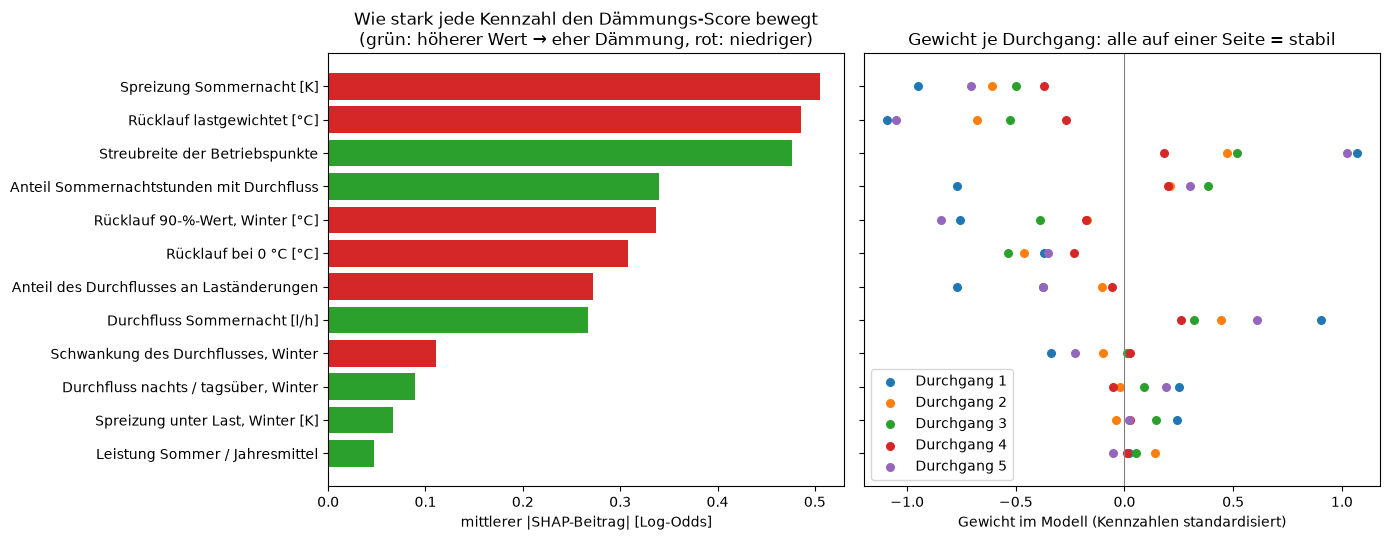

In [42]:
reihe = stabil.index[::-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
farben = ["tab:green" if stabil.loc[k, "Gewicht im Mittel"] > 0 else "tab:red" for k in reihe]
ax1.barh([KZ_TEXT[k] for k in reihe], stabil.loc[reihe, "mittlerer |Beitrag|"], color=farben)
ax1.set_title("Wie stark jede Kennzahl den Dämmungs-Score bewegt\n(grün: höherer Wert → eher Dämmung, rot: niedriger)")
ax1.set_xlabel("mittlerer |SHAP-Beitrag| [Log-Odds]")
ax1.set_ylabel("")
for k in gewicht.index:
    ax2.scatter(gewicht.loc[k, reihe], [KZ_TEXT[c] for c in reihe], s=30)
ax2.axvline(0, color="gray", linewidth=0.8)
ax2.set_title("Gewicht je Durchgang: alle auf einer Seite = stabil")
ax2.set_xlabel("Gewicht im Modell (Kennzahlen standardisiert)")
ax2.legend([f"Durchgang {k + 1}" for k in gewicht.index])
fig.tight_layout()

In [43]:
fig.savefig(BILDER / "10_shap_daemmung.png", bbox_inches="tight")

### 7b · Wie hängt der Beitrag vom Wert ab?

Für die drei wichtigsten Kennzahlen ist jeder Punkt eine Teststation, grün mit und grau ohne Dämmungsbefund.

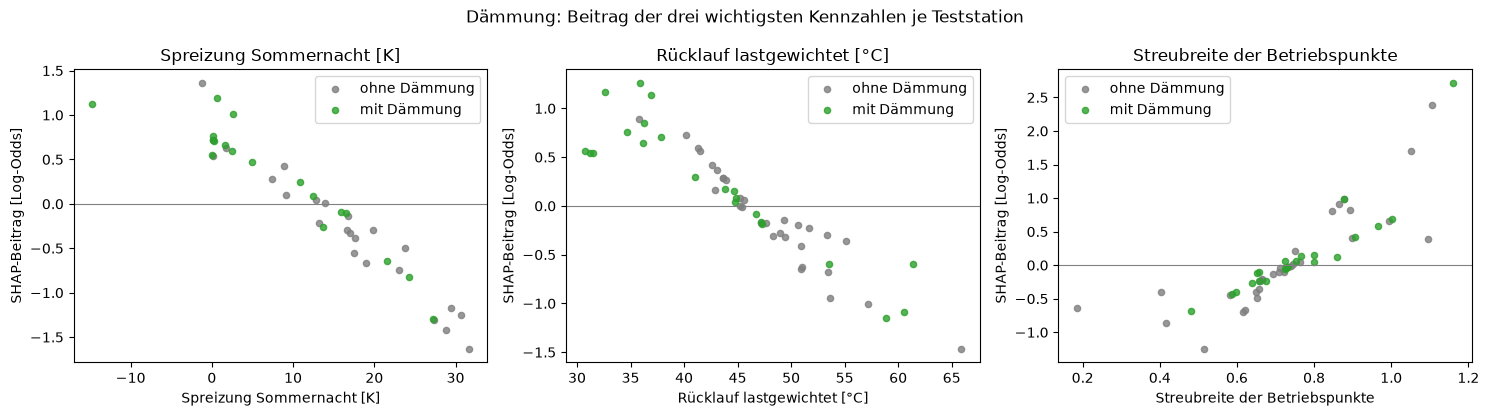

In [44]:
top = list(stabil.index[:3])
fig, achsen = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, k in zip(achsen, top):
    werte = X.reindex(S["shap"].index)[k]
    for wert, farbe in ((0, "tab:gray"), (1, "tab:green")):
        m = (S["y"] == wert).to_numpy()
        ax.scatter(werte[m], S["shap"].loc[m, k], color=farbe, s=20, alpha=0.8)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(KZ_TEXT[k])
    ax.set_xlabel(KZ_TEXT[k])
    ax.set_ylabel("SHAP-Beitrag [Log-Odds]")
    ax.legend(["ohne Dämmung", "mit Dämmung"])
fig.suptitle("Dämmung: Beitrag der drei wichtigsten Kennzahlen je Teststation")
fig.tight_layout()

In [45]:
fig.savefig(BILDER / "11_shap_abhaengigkeit.png", bbox_inches="tight")

Die wichtigsten Kennzahlen haben in allen fünf Durchgängen dasselbe Vorzeichen, das Muster ist also stabil und kein Zufall eines Durchgangs. Alle drei Rücklauf-Kennzahlen zeigen in dieselbe Richtung, je kälter der Rücklauf im Winter, desto eher gedämmt. Das passt zur Messlatte aus Notebook 25 (kälterer Rücklauf, 0,64) und zu 6f (weniger Volllaststunden), gedämmt wurde eher dort, wo die Station im Winter gut läuft. Bei der Spreizung in Sommernächten gilt, je kleiner, desto eher gedämmt. Wasser fließt, gibt aber kaum Wärme ab, und das kann ein Wärmeverlust über ungedämmte Leitungen sein, belegt ist es nicht. Bei der Streubreite der Betriebspunkte gilt, je größer, desto eher gedämmt. Die Beiträge hängen fast gerade vom Wert ab, wie es bei einer logistischen Regression sein muss, und gedämmte und nicht gedämmte Stationen mischen sich entlang der Linie. Keine Kennzahl trennt allein.

Die KI kombiniert also mehrere schwache Hinweise. Ein Teil davon beschreibt, wo gedämmt wurde, nämlich an gut laufenden Stationen, nicht warum. Das ist ein Grund mehr, die Dämmung im Dashboard nur als Hinweis zu zeigen.

### 7c · Hängt das Dämmungsmuster am Ventil?

6 der 11 Ventilstationen wurden auch gedämmt. Vielleicht erkennt das Modell die Dämmung nur, weil es den Ventilfehler sieht. Dann müsste es ohne die Ventilstationen deutlich schlechter werden. Gerechnet wird mit den Werten außerhalb des Folds aus Notebook 35.

In [46]:
o_d = oof[oof["ziel"] == "daemmung"].pivot_table(index="zaehler", columns="kandidat", values="p")
y_o = labels.reindex(o_d.index)["daemmung"].astype(int)
v_o = labels.reindex(o_d.index)["ventil"].astype(int)
regel = pd.read_csv(fv.AUSGABE / "ki_gegen_regel_vorhersagen.csv")
regel = regel[regel["ziel"] == "daemmung"].set_index("zaehler")["p"].reindex(o_d.index)
zeilen = []
for name, score in (("beste angepasste Regel", regel), ("LR Kennzahlen", o_d["LR Kennzahlen"]),
                    ("LR Kennzahlen + LSTM", o_d["LR Kennzahlen + LSTM"])):
    zeilen.append({"Modell": name, "alle 53": roc_auc_score(y_o, score),
                   f"ohne Ventilstationen ({int((v_o == 0).sum())})": roc_auc_score(y_o[v_o == 0], score[v_o == 0])})
print("Zum Vergleich: der Ventilbefund allein als Dämmungs-Score:", round(roc_auc_score(y_o, v_o), 3))
pd.DataFrame(zeilen).round(3)

Zum Vergleich: der Ventilbefund allein als Dämmungs-Score: 0.556


,Modell,alle 53,ohne Ventilstationen (42)
0,beste angepasste Regel,0.607,0.546
1,LR Kennzahlen,0.735,0.800
2,LR Kennzahlen + LSTM,0.802,0.822


Ohne die Ventilstationen wird die KI sogar besser (0,80 und 0,82), die Regel schlechter (0,55). Die KI erkennt die Dämmung also nicht über den Ventilfehler, und ohne Ventilstationen ist ihr Vorsprung vor der Regel noch größer als in Notebook 35.

### 7d · Variante mit Kennzahlen: Wie viel tragen die LSTM-Zahlen?

Geladen wird die gespeicherte Paket-Variante mit 12 Kennzahlen und 16 LSTM-Zahlen. Die 16 LSTM-Zahlen werden wie beim Lernen nur aus Tagen vor der Begehung berechnet. Das Dashboard nutzt seit der Modellwahl in Notebook 35 (Abschnitt 19.3) nur die LSTM-Zahlen, die Variante zeigt aber, wie viel sie neben den Kennzahlen tragen.

In [47]:
geladen = fk.lade("nb34_2026-10-25_121559")      #Paket-Variante mit 12 Kennzahlen und 16 LSTM-Zahlen
par = geladen["parameter"]
emb = fk.embeddings(geladen["netz"], geladen["skalierung"], e["stunden"], {"w2324": fk.WINTER, "s2024": fk.SOMMER},
                    grenze=grenze, min_tage=par.get("emb_min_tage", fk.EMB_MIN_TAGE))
X_paket = kz.join(emb).reindex(ids).reindex(columns=par["merkmale"])
sh_paket, basis_paket = mb.shap_linear(geladen["daemmung_modell"], X_paket)
p_paket = geladen["daemmung_modell"].predict_proba(X_paket)[:, 1]
print("Paket:", geladen["paket"].version)
print("Beiträge + Grundwert = Score:", np.allclose(1 / (1 + np.exp(-(sh_paket.sum(axis=1) + basis_paket))), p_paket))
lstm_spalten = [c for c in sh_paket.columns if c.startswith("lstm_")]
anteil_lstm = sh_paket[lstm_spalten].abs().sum(axis=1) / sh_paket.abs().sum(axis=1)
print(f"Anteil der 16 LSTM-Zahlen an allen Beiträgen je Station: Median {anteil_lstm.median():.0%}, "
      f"mittlere Hälfte {anteil_lstm.quantile(0.25):.0%} bis {anteil_lstm.quantile(0.75):.0%}")

Paket: nb34_2026-10-25_121559
Beiträge + Grundwert = Score: True
Anteil der 16 LSTM-Zahlen an allen Beiträgen je Station: Median 51%, mittlere Hälfte 46% bis 57%


Text(0, 0.5, '')

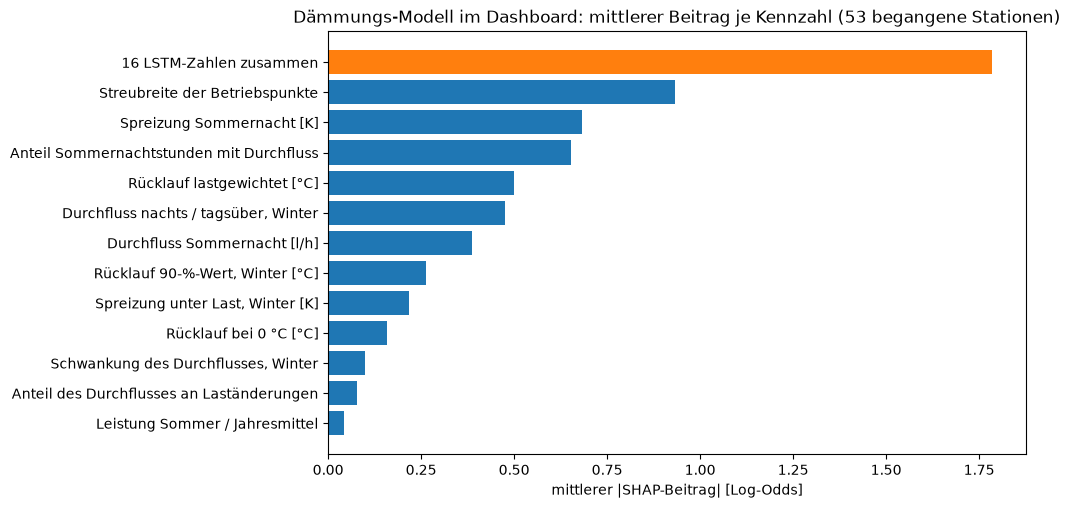

In [48]:
#Ein Paket nur mit den 16 LSTM-Zahlen hätte keine Kennzahlen, dann gibt es keine Kennzahlen-Spalten
kz_im_paket = [k for k in fv.KENNZAHLEN if k in sh_paket.columns]
if not kz_im_paket:
    print(f"Paket {geladen['paket'].version} ohne Kennzahlen, die Abbildung zeigt nur die LSTM-Zahlen")
gruppiert = pd.concat([sh_paket[kz_im_paket].rename(columns=KZ_TEXT),
                       sh_paket[lstm_spalten].sum(axis=1).rename("16 LSTM-Zahlen zusammen")], axis=1)
wichtig = gruppiert.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(wichtig.index, wichtig, color=["tab:orange" if k.startswith("16 LSTM") else "tab:blue" for k in wichtig.index])
ax.set_title("Dämmungs-Modell im Dashboard: mittlerer Beitrag je Kennzahl (53 begangene Stationen)")
ax.set_xlabel("mittlerer |SHAP-Beitrag| [Log-Odds]")
ax.set_ylabel("")

In [49]:
fig.savefig(BILDER / "12_shap_paket_lstm.png", bbox_inches="tight")

In dieser Variante tragen die 16 LSTM-Zahlen zusammen etwa die Hälfte des Dämmungs-Scores (Median 51 %), mehr als jede einzelne Kennzahl. Das passt zu Notebook 35, wo die LSTM-Zahlen die Dämmung von 0,73 auf 0,80 heben. Was sie bedeuten, kann SHAP nicht sagen. „LSTM-Zahl 5 ist hoch“ hilft einem Techniker vor Ort nicht, und das bleibt die Schwäche der LSTM-Zahlen. Das Modell ist auf allen 53 Stationen gelernt, SHAP erklärt hier also, was es tut, nicht wie gut es auf neuen Stationen ist. Wie gut es ist, steht in Notebook 35.

### 7e · Gegenprobe Ventil

Beim Ventil ist bekannt, worauf es ankommt, auf den Durchfluss in Sommernächten. Wenn SHAP richtig arbeitet, muss es das zeigen.

In [50]:
S_v = mb.shap_folds(X, oof, gruppen, "ventil", "LR Kennzahlen", fv.KENNZAHLEN)
gv = S_v["gewichte"]
pd.DataFrame({"mittlerer |Beitrag|": S_v["shap"][fv.KENNZAHLEN].abs().mean(), "Gewicht im Mittel": gv.mean(),
              "Durchgänge mit gleichem Vorzeichen": (np.sign(gv) == np.sign(gv.mean())).sum()}
             ).sort_values("mittlerer |Beitrag|", ascending=False).head(5).round(3)

,mittlerer |Beitrag|,Gewicht im Mittel,Durchgänge mit gleichem Vorzeichen
sommer_durchlauf_anteil,0.592,0.752,5
sommer_nachtfluss_lph,0.380,0.565,5
sommer_nacht_spreizung_k,0.339,0.363,5
sommerlast_anteil,0.232,0.297,5
winter_spreizung_last_k,0.207,0.211,4


Die Gegenprobe stimmt. Beim Ventil stützt sich das Modell auf die Sommernächte, also den Anteil der Stunden mit Durchfluss, den Durchfluss und die Spreizung, alle in allen fünf Durchgängen mit demselben Vorzeichen. SHAP zeigt also, was die Physik erwarten lässt.

## 8 · Steckt ein äußerer Faktor dahinter?

Nach Abschnitt 7 bleibt die Frage, ob die KI wirklich die Dämmung erkennt oder einen äußeren Faktor, der beides beeinflusst, ob gedämmt wird und wie die Station läuft, zum Beispiel das Alter oder die Art des Hauses. So ein Faktor heißt Störfaktor.

Im Begehungsprotokoll stehen einige Gebäudeangaben, allerdings lückenhaft: die Anlagenkennziffer bei allen, der Stationstyp bei den meisten, Wohnfläche, Personen und Baujahr bei weniger als der Hälfte und eine Zusatzheizung wie Holzofen oder Solarthermie nur, wenn sie vorhanden ist. Dazu kommen aus den Zählerdaten der Anschlusswert und der mittlere Tagesverbrauch vor der Begehung als Maß für die Größe sowie Zeitraum und Tag der Begehung, die für verschiedene Teams oder Gewohnheiten stehen können.

Vorher festgelegt ist, was zu erwarten wäre. Ist ein Faktor der Störfaktor, unterscheidet sich der Anteil gedämmter Stationen je nach Faktor deutlich, und innerhalb der Gruppen dieses Faktors trennt die KI nicht mehr, die AUC fällt Richtung 0,5. Sind die Labels verwässert, verstecken sich also unter den leeren Kästchen Dämmungsfälle, sehen die leeren Stationen eher aus wie die „ja“-Stationen als wie die ausdrücklichen „nein“. Die Richtung der einzelnen Faktoren ist offen, deshalb wird beidseitig geprüft. Die Angaben stammen aus dem Protokoll und existieren nur für begangene Stationen. Sie taugen zum Prüfen, nicht als Kennzahl für das Dashboard, und die Gebäudeangaben einzelner Häuser werden nicht gespeichert.

### 8a · Was heißt ein leeres Kästchen?

Ein Zähler gilt als „ja“, wenn bei einer Begehung das Kästchen „Leitungen neu gedämmt“ angekreuzt ist oder der Freitext einen Dämmungsbefund nennt, als „ausdrücklich nein“, wenn „nein“ eingetragen ist, und sonst als „leer“. Im Modell zählen „leer“ und „nein“ beide als „nicht gedämmt“.

In [51]:
G = mb.daemmung_und_gebaeude(labels.index).reindex(ids)
print("„ja“ stimmt mit dem Dämmungs-Label überein:", bool(((G["daemmung_eintrag"] == "ja") == labels.reindex(ids)["daemmung"]).all()))

ki_d = oof[(oof["ziel"] == "daemmung") & (oof["kandidat"] == "LR Kennzahlen + LSTM")].set_index("zaehler")["p"]
V = G.join(ki_d.rename("ki_score")).join(NK[["abkuehlrate_stillstand"]]).join(NK_an[["volllaststunden"]])
V = V.join(kz[["ruecklauf_lastgewichtet"]])
V["anschlusswert_kw"] = pd.Series(e["anschluss"]).reindex(V.index)
V["verbrauch_kwh_tag"] = T[T["tag"] < T["zaehler"].map(grenze)].groupby("zaehler")["energie_kwh"].mean().reindex(V.index)
V["daemmung"] = labels.reindex(V.index)["daemmung"].astype(int)

GROESSEN = {"ki_score": "KI-Score Dämmung (Notebook 35)", "abkuehlrate_stillstand": "Abkühlrate im Stillstand [je Stunde]",
            "volllaststunden": "Volllaststunden [h]", "ruecklauf_lastgewichtet": "Rücklauf lastgewichtet [°C]"}
EINTRAG = ["ja", "leer", "ausdrücklich nein"]
V.groupby("daemmung_eintrag")[list(GROESSEN)].median().reindex(EINTRAG).assign(Stationen=V["daemmung_eintrag"].value_counts()).round(3)

„ja“ stimmt mit dem Dämmungs-Label überein: True


,ki_score,abkuehlrate_stillstand,volllaststunden,ruecklauf_lastgewichtet,Stationen
daemmung_eintrag,,,,,
ja,0.618,0.232,1175.732,42.398,22
leer,0.411,0.187,1611.103,47.645,25
ausdrücklich nein,0.375,0.177,1789.154,46.750,6


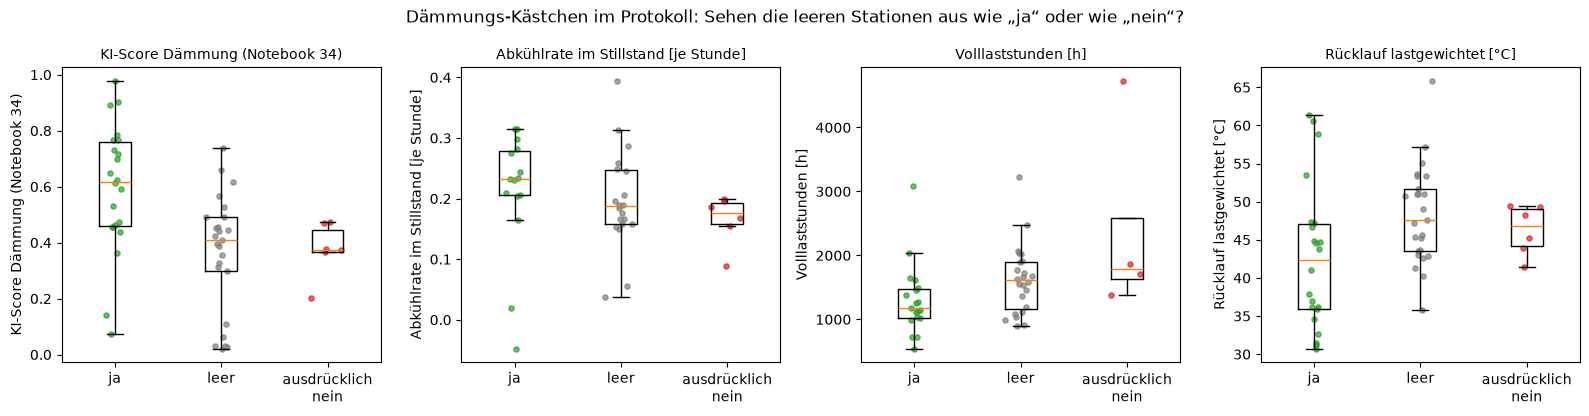

In [52]:
fig, achsen = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (spalte, name) in zip(achsen, GROESSEN.items()):
    werte = [V.loc[V["daemmung_eintrag"] == g, spalte].dropna() for g in EINTRAG]
    ax.boxplot(werte, showfliers=False)
    for i, w in enumerate(werte, start=1):
        ax.scatter(np.random.default_rng(i).normal(i, 0.06, len(w)), w, s=14, alpha=0.7,
                   color=["tab:green", "tab:gray", "tab:red"][i - 1])
    ax.set_xticks([1, 2, 3], ["ja", "leer", "ausdrücklich\nnein"])
    ax.set_title(name, fontsize=10)
    ax.set_ylabel(name)
fig.suptitle("Dämmungs-Kästchen im Protokoll: Sehen die leeren Stationen aus wie „ja“ oder wie „nein“?")
fig.tight_layout()

In [53]:
fig.savefig(BILDER / "13_daemmung_eintrag.png", bbox_inches="tight")

In [54]:
zeilen = []
for spalte, name in GROESSEN.items():
    for a, b in (("ja", "ausdrücklich nein"), ("ja", "leer"), ("leer", "ausdrücklich nein")):
        d = V[V["daemmung_eintrag"].isin([a, b])].dropna(subset=[spalte])
        zeilen.append({"Größe": name, "Vergleich": f"{a} gegen {b}",
                       "Stationen": f"{(d['daemmung_eintrag'] == a).sum()} / {(d['daemmung_eintrag'] == b).sum()}",
                       "AUC (höherer Wert = erste Gruppe)": roc_auc_score(d["daemmung_eintrag"] == a, d[spalte])})
LE = pd.DataFrame(zeilen)
LE.round(3)

,Größe,Vergleich,Stationen,AUC (höherer Wert = erste Gruppe)
0,KI-Score Dämmung (Notebook 34),ja gegen ausdrücklich nein,22 / 6,0.811
1,KI-Score Dämmung (Notebook 34),ja gegen leer,22 / 25,0.800
2,KI-Score Dämmung (Notebook 34),leer gegen ausdrücklich nein,25 / 6,0.520
3,Abkühlrate im Stillstand [je Stunde],ja gegen ausdrücklich nein,15 / 6,0.822
4,Abkühlrate im Stillstand [je Stunde],ja gegen leer,15 / 20,0.643
5,Abkühlrate im Stillstand [je Stunde],leer gegen ausdrücklich nein,20 / 6,0.592
6,Volllaststunden [h],ja gegen ausdrücklich nein,19 / 4,0.145
7,Volllaststunden [h],ja gegen leer,19 / 24,0.309
8,Volllaststunden [h],leer gegen ausdrücklich nein,24 / 4,0.333
9,Rücklauf lastgewichtet [°C],ja gegen ausdrücklich nein,22 / 6,0.303


Die leeren Kästchen sehen aus wie die ausdrücklichen „nein“, nicht wie die „ja“. Der KI-Score liegt im Median bei 0,41 (leer) und 0,38 (nein) gegen 0,62 (ja), und leer gegen nein trennt die KI nicht (0,52). Auch bei Abkühlrate, Volllaststunden und Rücklauf liegen die leeren jeweils näher bei „nein“ als bei „ja“. Ein leeres Kästchen heißt hier also meistens wirklich „nicht gedämmt“. Unter den leeren verstecken sich kaum Dämmungsfälle, und das Label ist an dieser Stelle nicht verwässert. Allerdings gibt es nur 6 ausdrückliche „nein“.

### 8b · Hängt die Dämmung an Gebäude, Größe oder Begehung?

Für jede Angabe zählt, wie oft gedämmt wurde. Bei Gruppen wie Anlagenkennziffer, Stationstyp, Zusatzheizung und Zeitraum der Begehung prüft ein Zufallstest auf Unterschiede zwischen den Gruppen, bei Zahlen die AUC, beidseitig. Neun Angaben heißen neun Tests, deshalb wird wieder nach Holm korrigiert.

In [55]:
datum = labels.reindex(V.index)["erste_begehung"]
V["anlage"] = V["anlagenkennziffer"].where(V["anlagenkennziffer"].isin(["2.1", "3.1", "4.1"]), "andere")
V["zeitraum"] = np.select([datum.isna(), datum < "2024-10-01", datum < "2025-01-01"],
                          ["ohne Datum", "Aug. bis Sep. 2024", "Okt. bis Dez. 2024"], "2025")
V["begehungstag"] = datum.dt.strftime("%Y-%m-%d").fillna("ohne Datum")
V["zusatzheizung_text"] = np.where(V["zusatzheizung"], "eingetragen", "keine eingetragen")

GRUPPEN = {"anlage": "Anlagenkennziffer", "stationstyp": "Stationstyp", "zusatzheizung_text": "Zusatzheizung",
           "zeitraum": "Zeitraum der Begehung"}
zeilen, tests = [], []
for spalte, name in GRUPPEN.items():
    p = mb.gruppen_zufallstest(V[spalte], V["daemmung"])
    tests.append({"Angabe": name, "Stationen mit Angabe": int(V[spalte].notna().sum()), "Maß": "Anteile je Gruppe", "p": p})
    for wert, teil in V.groupby(spalte):
        zeilen.append({"Angabe": name, "Gruppe": wert, "Stationen": len(teil), "gedämmt": int(teil["daemmung"].sum()),
                       "Anteil gedämmt": round(teil["daemmung"].mean(), 2)})
GA = pd.DataFrame(zeilen)
GA

,Angabe,Gruppe,Stationen,gedämmt,Anteil gedämmt
0,Anlagenkennziffer,2.1,27,7,0.26
1,Anlagenkennziffer,3.1,13,7,0.54
2,Anlagenkennziffer,4.1,9,5,0.56
3,Anlagenkennziffer,andere,4,3,0.75
4,Stationstyp,Comfort,5,0,0.00
5,Stationstyp,GIRO 0H,27,9,0.33
6,Stationstyp,GIRO 1H,11,8,0.73
7,Stationstyp,GIRO ohne Typ,3,1,0.33
8,Stationstyp,keine Angabe,7,4,0.57
9,Zusatzheizung,eingetragen,12,4,0.33


In [56]:
ZAHLEN = {"anschlusswert_kw": "Anschlusswert [kW]", "verbrauch_kwh_tag": "Tagesverbrauch vorher [kWh]",
          "wohnflaeche": "Wohnfläche [m²]", "personen": "Personen", "baujahr": "Baujahr"}
zeilen = []
for spalte, name in ZAHLEN.items():
    r = mb.plan_pruefen(V[spalte], V["daemmung"], gruppen, 0)
    zeilen.append({"Angabe": name, "Stationen": r["Stationen"], "gedämmt": r["mit Befund"], "Median gedämmt": r["Median mit"],
                   "Median nicht gedämmt": r["Median ohne"], "AUC (höher = gedämmt)": r["AUC"], "unten": r["unten"], "oben": r["oben"]})
    tests.append({"Angabe": name, "Stationen mit Angabe": r["Stationen"], "Maß": f"AUC {r['AUC']:.2f}", "p": r["p"]})
GZ = pd.DataFrame(zeilen)
GT = pd.DataFrame(tests)
GT["p nach Holm"] = mb.holm(GT["p"])
display(GZ.round(3))
GT.round(3)

,Angabe,Stationen,gedämmt,Median gedämmt,Median nicht gedämmt,AUC (höher = gedämmt),unten,oben
0,Anschlusswert [kW],52,22,8.000,10.500,0.361,0.209,0.514
1,Tagesverbrauch vorher [kWh],53,22,34.421,54.284,0.343,0.201,0.498
2,Wohnfläche [m²],24,10,190.000,175.000,0.471,0.242,0.718
3,Personen,21,10,3.000,2.000,0.509,0.259,0.760
4,Baujahr,14,8,2014.500,2011.000,0.771,0.469,1.000


,Angabe,Stationen mit Angabe,Maß,p,p nach Holm
0,Anlagenkennziffer,53,Anteile je Gruppe,0.121,0.604
1,Stationstyp,53,Anteile je Gruppe,0.044,0.398
2,Zusatzheizung,53,Anteile je Gruppe,0.743,1.000
3,Zeitraum der Begehung,53,Anteile je Gruppe,0.708,1.000
4,Anschlusswert [kW],52,AUC 0.36,0.088,0.542
5,Tagesverbrauch vorher [kWh],53,AUC 0.34,0.051,0.406
6,Wohnfläche [m²],24,AUC 0.47,0.820,1.000
7,Personen,21,AUC 0.51,0.977,1.000
8,Baujahr,14,AUC 0.77,0.077,0.542


In [57]:
print("Volllaststunden (Median) mit Zusatzheizung:", round(V.loc[V["zusatzheizung"], "volllaststunden"].median()),
      "| ohne:", round(V.loc[~V["zusatzheizung"], "volllaststunden"].median()))

Volllaststunden (Median) mit Zusatzheizung: 1254 | ohne: 1519


Beim Stationstyp ist der Unterschied am deutlichsten. Beim Typ „GIRO 1H“ wurde bei 8 von 11 Stationen gedämmt, bei „GIRO 0H“ bei 9 von 27 und beim Typ „Comfort“ bei keiner von 5 (p = 0,04, nach Holm 0,40, nicht gesichert). Bei der Anlagenkennziffer 2.1 wurde seltener gedämmt (7 von 27) als bei 3.1 und 4.1, wo es etwa jede zweite Station war, auch das nicht gesichert. Was die Ziffern bedeuten, steht nicht im Protokoll. Gedämmt wurde eher an kleineren Stationen mit weniger Verbrauch (Median 34 gegen 54 kWh am Tag, AUC 0,34), knapp nicht gesichert, was zu den Volllaststunden aus 6f passt. Das Baujahr ist nur bei 14 Stationen bekannt, und gedämmt wurde dort eher bei neueren Häusern (Median 2014 gegen 2011), nicht bei älteren (p = 0,08). Stationen mit Holzofen oder Solarthermie haben zwar weniger Volllaststunden (Median 1254 gegen 1519), wurden aber nicht häufiger gedämmt (4 von 12) und erklären das Muster nicht. Bei Zeitraum der Begehung, Wohnfläche und Personen gibt es keinen Unterschied. Nach Holm ist keine Angabe gesichert, mit 53 Stationen wäre ein mittelgroßer Störfaktor allerdings auch schwer zu sehen.

### 8c · Trennt die KI auch innerhalb der Gruppen?

Im schärferen Test darf die KI nur noch Stationen derselben Gruppe vergleichen, also zum Beispiel nur kleine mit kleinen und große mit großen. Erkennt sie eigentlich den Faktor, fällt diese AUC auf etwa 0,5, erkennt sie etwas anderes, bleibt sie hoch. „Paare“ ist die Zahl der Vergleiche aus gedämmter und nicht gedämmter Station, die dabei übrig bleiben. Je weniger es sind, desto unsicherer ist das Ergebnis.

In [58]:
V["groesse"] = np.where(V["anschlusswert_kw"] >= V["anschlusswert_kw"].median(), "größere Hälfte", "kleinere Hälfte")
V["verbrauch"] = np.where(V["verbrauch_kwh_tag"] >= V["verbrauch_kwh_tag"].median(), "mehr Verbrauch", "weniger Verbrauch")
INNERHALB = {"anlage": "Anlagenkennziffer", "stationstyp": "Stationstyp", "zusatzheizung_text": "Zusatzheizung",
             "groesse": "Anschlusswert (Hälften)", "verbrauch": "Tagesverbrauch (Hälften)", "zeitraum": "Zeitraum der Begehung",
             "begehungstag": "Tag der Begehung"}
zeilen = [{"KI vergleicht nur innerhalb von": "(alle Stationen)", "AUC": roc_auc_score(V["daemmung"], V["ki_score"]),
           "Paare": int(V["daemmung"].sum() * (1 - V["daemmung"]).sum())}]
for spalte, name in INNERHALB.items():
    a, n = mb.auc_innerhalb(V["daemmung"], V["ki_score"], V[spalte])
    zeilen.append({"KI vergleicht nur innerhalb von": name, "AUC": a, "Paare": n})
KI_IN = pd.DataFrame(zeilen)
KI_IN.round(3)

,KI vergleicht nur innerhalb von,AUC,Paare
0,(alle Stationen),0.802,682
1,Anlagenkennziffer,0.746,205
2,Stationstyp,0.855,200
3,Zusatzheizung,0.827,446
4,Anschlusswert (Hälften),0.782,330
5,Tagesverbrauch (Hälften),0.798,331
6,Zeitraum der Begehung,0.750,272
7,Tag der Begehung,0.950,20


Text(0, 0.5, '')

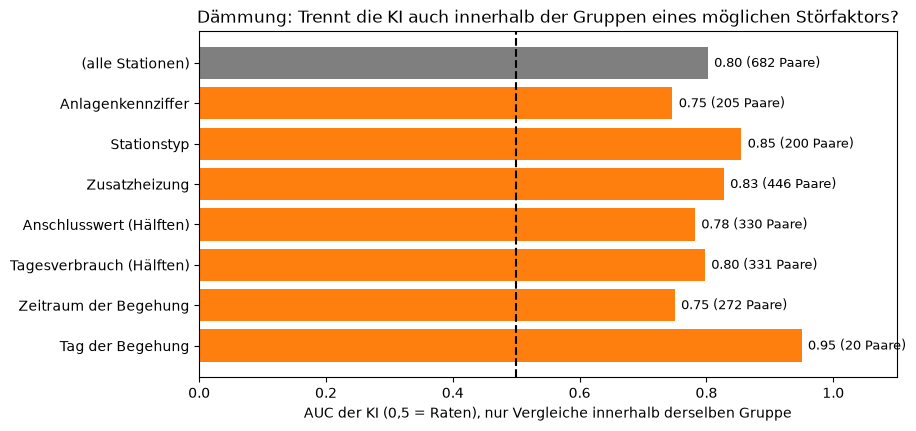

In [59]:
fig, ax = plt.subplots(figsize=(9, 4.5))
reihe = KI_IN.iloc[::-1]
ax.barh(reihe["KI vergleicht nur innerhalb von"], reihe["AUC"], color=["tab:gray" if i == 0 else "tab:orange" for i in reihe.index])
for y, (a, n) in enumerate(zip(reihe["AUC"], reihe["Paare"])):
    ax.text(a + 0.01, y, f"{a:.2f} ({n} Paare)", va="center", fontsize=9)
ax.axvline(0.5, color="black", linestyle="--")
ax.set_xlim(0, 1.1)
ax.set_title("Dämmung: Trennt die KI auch innerhalb der Gruppen eines möglichen Störfaktors?")
ax.set_xlabel("AUC der KI (0,5 = Raten), nur Vergleiche innerhalb derselben Gruppe")
ax.set_ylabel("")

In [60]:
fig.savefig(BILDER / "14_ki_innerhalb.png", bbox_inches="tight")

Bei keinem Faktor fällt die KI Richtung 0,5. Innerhalb der Gruppen liegt sie zwischen 0,75 und 0,86, also fast so hoch wie insgesamt (0,80). Am meisten verliert sie bei Anlagenkennziffer und Zeitraum (0,75). Der Tag der Begehung lässt nur 20 Paare übrig und sagt deshalb wenig. Keine der vorhandenen Angaben erklärt also, warum die KI die Dämmung erkennt. Ein unbekannter Störfaktor ist damit nicht ausgeschlossen, denn das Baujahr fehlt bei 39 der 53 Stationen, und das Alter der Station selbst steht nirgends. Dafür bräuchte es Angaben vom Projektpartner.

## 9 · Was daraus folgt

| Befund | Wirkung nach der Maßnahme messbar? | beste neue Kennzahl | KI (Kennzahlen + LSTM) | Stand |
|---|---|---|---|---|
| Ventil | ja, klar (6 von 8) | nicht nötig | 0,82 | erkennbar und wirksam |
| Dämmung | im Verbrauch nein; Abkühlung danach langsamer (Hinweis) | Abkühlrate 0,69, nach Holm nicht gesichert | 0,80, ohne Ventilstationen 0,82 | erkennbar, kein bekannter Störfaktor, erster physikalischer Hinweis |
| Sollwert | Andeutung (Rücklauf −0,2 K) | keine | unter 0,5 | Label eher Routine (62 %) |
| Filter | nein | Sättigung 0,62, nicht gesichert | unter 0,5 | nicht erkennbar |
| Durchfluss | nein | keine | unter 0,5 | nicht erkennbar |
| Vertrag | Placebo, richtig keine Wirkung | keine, die alte Auslastungsregel ist besser | | Regel reicht |

Zur Ausgangsfrage: Bei Filter, Durchfluss und Sollwert liegt es nicht nur an den Kennzahlen. Die Maßnahmen hinterlassen auch nachher keine messbare Spur im Zähler, und die Labels sind eher Routine, mit besseren Kennzahlen allein ist dort wenig zu holen. Bei der Dämmung gibt es jetzt eine erste physikalische Spur, die Abkühlrate, noch nicht gesichert.

Mit allem, was im Protokoll steht, lässt sich das Dämmungsmuster der KI nicht erklären. Gedämmt wurde etwas häufiger an kleineren Stationen und bei einem Stationstyp, aber innerhalb dieser Gruppen erkennt die KI die Dämmung genauso. Offen bleibt ein unbekannter Faktor, vor allem das Alter von Haus und Station. Der Vorsprung der KI bei der Dämmung (0,80 gegen 0,61 für die beste Regel) bleibt also bestehen und hängt nicht am Ventil.

Für das Dashboard ändert sich nichts, die Dämmung bleibt ein Hinweis. Die Abkühlrate wäre eine gute, verständliche Begründung („Wasser kühlt im Stillstand schneller ab als bei vergleichbaren Stationen“), sobald sie an neuen Daten bestätigt ist.

Für bessere Labels sollte bei der Begehung notiert werden, ob etwas kaputt war, nicht nur, was gemacht wurde. Maßnahmen ohne messbare Wirkung sollten nicht als Fehler zählen, was beim Ventil schon heute ginge (4d). Für Dämmung und Filter sollte vorher und nachher gezielt gemessen werden, die Abkühlrate im Stillstand und der Durchfluss an kalten Tagen. Und das Baujahr von Haus und Station sollte für alle Stationen beim Projektpartner erfragt werden, denn erst damit lässt sich der letzte mögliche Störfaktor prüfen. Als Nächstes wäre die Abkühlrate an neuen Daten zu prüfen, diesmal vorher festgelegt. Hält sie, kommt sie als Kennzahl in die Regression und als Begründung ins Dashboard, und die Filter-Sättigung im nächsten Winter genauso.

Unterwegs wurden drei Deutungen korrigiert. Die Volllaststunden waren für den Vertrag gedacht und haben dort nichts gebracht, stattdessen schienen sie die Dämmung stark zu verbessern, und erst das Zerlegen in 6f hat gezeigt, dass der Sprung an der Bezugsgröße hängt. Die Nachprüfung der Abkühlrate (6c) sah zuerst sehr deutlich aus (p = 0,002), erst die Rückkehr zur Mitte und eine unmögliche Messung haben sie auf einen Hinweis zurückgestuft. Und die Vermutung „älteres Haus, eher gedämmt“ stimmt nicht, wo das Baujahr bekannt ist, wurde eher bei neueren Häusern gedämmt (nur 14 Stationen, nicht gesichert).

## 10 · Ergebnisse speichern

Alles landet in `outputs/merkmalsbau/`, wie alle Ausgaben nicht im Git.

In [61]:
WT.to_csv(AUSGABE / "wirkung_tests.csv", index=False)
ZT.to_csv(AUSGABE / "wirkung_zusatz_kopplung.csv", index=False)
WA.to_csv(AUSGABE / "wirkung_anteil.csv", index=False)
W.to_csv(AUSGABE / "wirkung_je_station.csv")
NK.to_csv(AUSGABE / "neue_kennzahlen.csv")
KT.to_csv(AUSGABE / "neue_kennzahlen_tests.csv", index=False)
uebersicht.to_csv(AUSGABE / "neue_kennzahlen_uebersicht.csv")
RT.to_csv(AUSGABE / "regression_mit_neuen.csv", index=False)
RT_an.to_csv(AUSGABE / "regression_mit_neuen_anschlusswert.csv", index=False)
ZG.to_csv(AUSGABE / "zugewinn_daemmung_je_kennzahl.csv", index=False)
A.to_csv(AUSGABE / "abkuehlrate_vorher_nachher.csv")
NT.to_csv(AUSGABE / "nachtrag_abkuehlrate.csv", index=False)
LE.to_csv(AUSGABE / "daemmung_eintrag_vergleich.csv", index=False)
GA.to_csv(AUSGABE / "daemmung_je_gruppe.csv", index=False)
GT.to_csv(AUSGABE / "daemmung_faktoren_tests.csv", index=False)
KI_IN.to_csv(AUSGABE / "ki_innerhalb_der_gruppen.csv", index=False)
RM.to_csv(AUSGABE / "nachtrag_abkuehlrate_gleicher_start.csv", index=False)
stabil.to_csv(AUSGABE / "shap_daemmung_stabilitaet.csv")
S["shap"].to_csv(AUSGABE / "shap_daemmung_je_station.csv")
gruppiert.to_csv(AUSGABE / "shap_daemmung_paket.csv")
print(sorted(p.name for p in AUSGABE.glob("*.csv")))

['abkuehlrate_vorher_nachher.csv', 'daemmung_eintrag_vergleich.csv', 'daemmung_faktoren_tests.csv', 'daemmung_je_gruppe.csv', 'ki_innerhalb_der_gruppen.csv', 'nachtrag_abkuehlrate.csv', 'nachtrag_abkuehlrate_gleicher_start.csv', 'neue_kennzahlen.csv', 'neue_kennzahlen_tests.csv', 'neue_kennzahlen_uebersicht.csv', 'regression_mit_neuen.csv', 'regression_mit_neuen_anschlusswert.csv', 'shap_daemmung_je_station.csv', 'shap_daemmung_paket.csv', 'shap_daemmung_stabilitaet.csv', 'wirkung_anteil.csv', 'wirkung_je_station.csv', 'wirkung_tests.csv', 'wirkung_zusatz_kopplung.csv', 'zugewinn_daemmung_je_kennzahl.csv']


## Zusammenfassung & Bewertung

**Ergebnis**

Nur der Ventiltausch hinterlässt eine klare Spur, danach sinkt der Durchfluss in Sommernächten (AUC 0,81, nach Holm gesichert, 6 von 8 Stationen). Dämmung, Filter und Durchfluss hinterlassen keine messbare Spur, beim Sollwert gibt es höchstens eine Andeutung, und das Placebo Vertrag findet richtigerweise nichts. Sollwert (62 % der Begehungen) und Filter (47 %) sind eher Routine als gefundene Fehler. Die Abkühlrate im Stillstand gibt bei der Dämmung einen ersten physikalischen Hinweis (0,69, Richtung vorher festgelegt, nach Holm nicht gesichert). Nach SHAP erkennt die Regression die Dämmung an einem stabilen Muster aus kälterem Rücklauf, kleiner Spreizung in Sommernächten und großer Streubreite, in allen fünf Durchgängen gleich und auch ohne die Ventilstationen.

**Belastbar**

Größe und Richtung je Befund standen vor dem Rechnen fest (`PLAN_WIRKUNG`, `PLAN_KENNZAHLEN`), mit Holm über alle Tests und Intervallen über ganze Stationen. Gerechnet wird auf denselben 53 Stationen und Durchgängen wie Test C in Notebook 35, und mit 12 Kennzahlen ist das dort genau nachgerechnet (Abweichung 0).

**Schwach**

Je Befund gibt es wenige Fälle. Die Nachprüfung der Abkühlrate (9 von 10 Stationen) ist nachträglich ergänzt und hängt an einer fragwürdigen Messung, ein Hinweis, kein Beweis. Der Sprung der Dämmung in der Regression mit neuen Kennzahlen (0,74 auf 0,89) kommt von den Volllaststunden und hängt an der Bezugsgröße, er ist kein Ergebnis.

**Offen**

Abkühlrate und Filter-Sättigung sollten an neuen Daten geprüft werden, mit vorher festgelegter Richtung. Das Baujahr von Haus und Station wäre bei der ÜZ zu erfragen, um den letzten möglichen Störfaktor der Dämmung zu prüfen. Und bei Begehungen sollte notiert werden, ob etwas kaputt war, nicht nur, was gemacht wurde.